# HA2 — пространство и движение: baseline, HA1 и perturbation

**Роли 3–4.** Адаптация `Seminars/Class03/Class_03_Instructor_Working_Notebook.ipynb` под результаты ролей 1–2; общий выполненный notebook для baseline, покрытия HA1 и нового perturbation.

Входной снимок: [обновлённые raw-данные main](https://github.com/noriginalno/embodied-ai-coolest-group/tree/e1916dff33a5f25eb263696e0f95088b4d95f168/HomeAssignment/HA2/raw), commit `e1916dff33a5f25eb263696e0f95088b4d95f168`. Подготовка формата, provenance и POS зафиксирована в `prepared_inputs.json`; код расчёта — по SHA-256 в `results/run_manifest.json`.

Цель: воспроизводимо собрать baseline, отдельную проверку C×S для HA1, последовательный эксперимент +3/−3 и все связанные таблицы, JSON-графы и изображения. Исходные концепты, признаки и связи не пересматриваются. Эксперимент работает на копиях.

[Итоговая интерпретация](INTERPRETATION.md) и [сценарий с удалением второго родителя](ROLE4.md).

## 0. Что изменено относительно преподавательского ноутбука

- `concepts.csv` / `semantic_edges.csv` заменены на переданные `nodes.csv` / `edges.csv`; демонстрационные cup/car и интернет-запросы удалены.
- Полный граф — `MultiDiGraph`: разные типы связей между одной парой не перезаписывают друг друга. Таксономия — `DiGraph` со **всеми** узлами, включая изолированные.
- Нет единственного `ROOT='concept'`: используются все корни наблюдаемого DAG. Компоненты не объединяются вымышленными гиперонимами.
- Глубина вычисляется по кратчайшему и самому длинному пути от любого наблюдаемого корня. Диапазоны сохраняются и для потомков узлов с несколькими родителями.
- Расчётные функции вынесены в соседний `ha2_analysis.py`, чтобы роль 4 использовала ту же реализацию.

Запуск: Python 3.13, зависимости в `requirements.txt`; **Run All** из корня репозитория, `HomeAssignment/HA2` или `Seminars/Class03`. Во время выполнения сеть не используется.

In [1]:
from pathlib import Path
import json
import sys
import importlib.metadata
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import Image, display

# Only explicit paths; no recursive search or machine-specific absolute path.
bases = [Path.cwd(), *list(Path.cwd().parents)[:3]]
candidates = [p for base in bases for p in (base, base / 'HomeAssignment/HA2')]
DATA_DIR = next((p.resolve() for p in candidates if all(
    (p / f).is_file() for f in ('nodes.csv', 'edges.csv', 'ha2_analysis.py')
)), None)
if DATA_DIR is None:
    raise FileNotFoundError('Run from repository root, HomeAssignment/HA2 or Seminars/Class03.')
sys.path.insert(0, str(DATA_DIR))
from ha2_analysis import (
    load_inputs, build_graphs, audit_directions, compute_specificity,
    validate_scores, export_results, draw_taxonomy, draw_non_taxonomic, save_figures,
)
from ha2_coverage import run_coverage
from ha2_perturbation import run_perturbation
from ha2_artifacts import render_artifacts, write_artifact_manifest, verify_artifacts
plt.rcParams.update({'font.family': 'DejaVu Sans', 'svg.hashsalt': 'ha2-role3'})
print('Data:', DATA_DIR.relative_to(DATA_DIR.parents[1]))
print('Python:', sys.version.split()[0])
print({p: importlib.metadata.version(p) for p in ('networkx', 'pandas', 'numpy', 'matplotlib')})

Data: HomeAssignment/HA2
Python: 3.13.5
{'networkx': '3.4.2', 'pandas': '2.3.3', 'numpy': '2.4.6', 'matplotlib': '3.10.0'}


## 1. Переданные данные и дополнительная метаинформация

`nodes.csv` / `edges.csv` читаются без изменений. Определения целевых узлов копируются из `raw/Concepts_hw2.csv`, без генерации; отсутствие определения у вспомогательного узла сохраняется.

Подготовленный `nodes.csv` содержит POS и его происхождение. Для 16 узлов POS прочитан из суффикса синсета; для 28 дана **ручная лексическая разметка**, привязанная к ID, термину и source_id. Все 44 названия — NOUN, включая имена процессов и состояний. ILI сам по себе не используется для вывода POS. Загрузчик отклоняет устаревшие CSV и POS-пометки для переиспользованных ID.

**Размер входа:** 44 узла, из них 25 целевых и 19 вспомогательных; 37 таксономических и 4 нетаксономических ребра. Указание 15–25 узлов относится к семинарским слайдам, а не к непосредственному перечню HA2 на слайде 33. Переданный инвентарь сохранён без изменений. Поле `source_provenance` сохраняет исходную пометку источника каждого ребра.

In [2]:
nodes, edges = load_inputs(DATA_DIR)
print(f'Узлов: {len(nodes)}; целевых: {nodes.is_target.eq("TRUE").sum()}; рёбер: {len(edges)}')
display(nodes[['node_id', 'label', 'node_type', 'POS', 'POS_provenance', 'definition']].head(12))
display(edges.groupby(['relation', 'provenance']).size().rename('count').to_frame())
display(nodes.groupby(['POS', 'POS_provenance']).size().rename('count').to_frame())

Узлов: 44; целевых: 25; рёбер: 41


,node_id,label,node_type,POS,POS_provenance,definition
0,C01,точка,target,NOUN,wordnet:source_id_suffix,"Определённое положение в пространстве, рассмат..."
1,C02,поверхность,target,NOUN,wordnet:source_id_suffix,"Внешняя граница тела, отделяющая его от окружа..."
2,C03,граница,target,NOUN,wordnet:source_id_suffix,"Предел, отделяющий одну пространственную облас..."
3,C04,расстояние,target,NOUN,wordnet:source_id_suffix,"Пространственная величина, характеризующая уда..."
4,C05,высота,target,NOUN,wordnet:source_id_suffix,Вертикальное расстояние от точки или объекта д...
5,C06,направление,target,NOUN,wordnet:source_id_suffix,Ориентация в пространстве относительно выбранн...
6,C07,путь,target,NOUN,wordnet:source_id_suffix,"Маршрут, по которому перемещаются между исходн..."
7,C08,вместилище,target,NOUN,wordnet:source_id_suffix,"Ограниченный участок пространства, предназначе..."
8,C09,отверстие,target,NOUN,wordnet:source_id_suffix,"Пустое пространство в теле или материале, чере..."
9,C10,ширина,target,NOUN,manual:pos_annotations.csv,"Поперечный размер объекта, измеряемый как расс..."


,,count
relation,provenance,
affects_perceived_orientation,manual,1
describes_relative_proximity_between,manual,1
is_a,wordnet,37
orients_relative_to,manual,1
used_for_localization_of,manual,1


count
POS  POS_provenance                   
NOUN manual:pos_annotations.csv     28
     wordnet:source_id_suffix       16

## 2. Построение и проверка направлений

**Конвенция хранения:** `source=parent → target=child` для `is_a`. Это читается как **target is_a source**, а не наоборот. Нетаксономические предикаты читаются буквально, например «эхолокация → used_for_localization_of → место» и «головокружение → affects_perceived_orientation → ориентация».

Направления сверяются механически с колонками `source/target` в новом `raw/Edges.csv`. Старые alias, добавление родителей из прежней HA1-выгрузки и исключения не применяются. Это проверка переноса направления, **не повторная семантическая экспертиза гиперонимов**.

Проверяется DAG только для `is_a`: цикл в полном типизированном графе допустим. Никакие нетаксономические связи не становятся родителями.

In [3]:
G, T = build_graphs(nodes, edges)
direction_audit = audit_directions(DATA_DIR, nodes, edges)
assert direction_audit.source_direction_confirmed.all(), 'Unconfirmed source orientation'
assert set(G) == set(T) == set(nodes.node_id)
assert nx.is_directed_acyclic_graph(T)
print(f'Полный граф: {len(G)} узлов / {G.number_of_edges()} рёбер')
print(f'is_a: {len(T)} узлов / {T.number_of_edges()} рёбер; DAG=True')
print('Компонент is_a:', nx.number_weakly_connected_components(T))
print('Корней снимка:', sum(T.in_degree(n) == 0 for n in T))
print('Изолированные узлы снимка:', sorted(nx.isolates(T)))
print('Направлений подтверждено по исходным колонкам:', int(direction_audit.source_direction_confirmed.sum()))
display(direction_audit.head())

Полный граф: 44 узлов / 41 рёбер
is_a: 44 узлов / 37 рёбер; DAG=True
Компонент is_a: 9
Корней снимка: 15
Изолированные узлы снимка: []
Направлений подтверждено по исходным колонкам: 37


,source,relation,target,direction,source_direction_confirmed,evidence
0,A01,is_a,A02,parent_to_child,True,raw/Edges.csv: source -> target (parent -> child)
1,A01,is_a,A05,parent_to_child,True,raw/Edges.csv: source -> target (parent -> child)
2,A02,is_a,A03,parent_to_child,True,raw/Edges.csv: source -> target (parent -> child)
3,A03,is_a,A04,parent_to_child,True,raw/Edges.csv: source -> target (parent -> child)
4,A05,is_a,C12,parent_to_child,True,raw/Edges.csv: source -> target (parent -> child)


## 3. Формулы: расхождения в источниках и принятые правила

Источники: `Class_03_Semantic_Networks_Lecture_and_Seminar_Expanded_Lecture.pptx`, слайды **9–10, 28**; исходный notebook, раздел 4 / ячейки 14–15 (нумерация с нуля).

Обозначения для выбранного `is_a`-DAG: $d_{min}(v)$ / $d_{max}(v)$ — минимальная / максимальная длина пути от **любого наблюдаемого корня**; корень имеет глубину 0. $n(v)$ — число **различных достижимых потомков**, не число путей, рёбер или непосредственных детей. $D_s=\max_v d_{min}(v)$, $D_l=\max_v d_{max}(v)$, $B=\max_v n(v)$.

| Вариант | Формула / область | Как сохраняется |
|---|---|---|
| Лекция 9 + notebook | $S_{depth}=d_{min}/D_s$ | Основной `S_depth`, глобально по всему переданному DAG |
| Лекция 10 + верх слайда 28 + notebook | $S_{breadth}=1-\ln(1+n)/\ln(1+B)$ | Основной `S_breadth`, та же глобальная область |
| Несколько путей / родителей | $[d_{min},d_{max}]$ | Сырые границы и нормированный интервал $[d_{min}/D_l,d_{max}/D_l]$ |
| Нижние инструкции слайда 28: нормировать внутри POS | Те же две формулы на **индуцированном** графе каждого POS | Дополнительные `S_depth_pos`, `S_breadth_pos` |
| Нижняя формула слайда 28 | $A=d+\ln((1+n)/N_{POS})$ | Отдельные `slide28_raw_min/max`; $d$ интерпретировано как $d_{min/max}$, $n$ как потомки; значения POS-restricted |

Последняя формула **не эквивалентна** inverse-descendant: при фиксированных $d,N$ её значение растёт с числом потомков. Значения $d$ и $n$ в этой строке слайда не определены отдельно — выбранная трактовка явно является допущением реализации. Основные два S ею не подменяются. Для диагностического сравнения добавлена min–max-нормализация её варианта с кратчайшей глубиной **внутри POS**: $(A-A_{min})/(A_{max}-A_{min})$; это решение реализации, **не формула преподавателя**.

`S_depth_longest=d_max/D_l` — альтернативный depth-score. Нормированный интервал всегда использует один $D_l$, чтобы верхняя граница не превышала 1. Основной `S_depth` использует $D_s$; если $D_s\ne D_l$, он не обязан совпадать с нижней границей интервала. В текущем снимке оба максимума равны 5.

### Область нормализации и неопределённые значения

- **Основная область — все 44 узла**, включая вспомогательные. Максимумы общие для всех компонентов, а не пересчитываются внутри каждого компонента. Искусственный суперкорень не добавляется даже временно.
- POS-вариант использует индуцированный подграф: меж-POS-рёбра не участвуют; его корни, глубины и потомки пересчитываются. Сохраняются $N$, оба максимума глубины, $B$, $\ln(1+B)$ и min/max альтернативной формулы.
- По fallback со слайда 28 при **N < 10** сохраняются сырые значения, нормированные оценки не выдаются (`NaN`, пустая ячейка CSV). Это относится к маленькой области нормализации, **не** к каждому маленькому компоненту внутри глобальной области.
- Нулевой знаменатель также даёт `NaN`, а не произвольный 0. В текущем снимке один POS=NOUN и 44 узла, поэтому глобальные и POS-оценки совпадают; отсутствующих ADP/ADV-групп в таблице нет.
- В этом baseline изолятов нет. Общий алгоритм сохраняет изоляты, если они появятся: формальные значения $d=0,n=0$ не доказывают их специфичность. Нулевое число потомков означает только отсутствие потомков **в этом снимке**, а не во всём RuWordNet.
- `ln` — натуральный логарифм; в основном breadth отношение не зависит от основания. Вычисления/CSV сохраняют точность float; округление применяется только при выводе таблиц. Смешанный `S_mean` не рассчитывается.

In [4]:
specificity, normalization_constants = compute_specificity(T)
validate_scores(T, specificity)
target_specificity = specificity.loc[specificity.is_target.eq('TRUE')].copy()
columns = ['node_id', 'label', 'parent_ids', 'depth_min', 'depth_max', 'descendants',
           'S_depth', 'S_breadth', 'S_depth_range_min', 'S_depth_range_max', 'taxonomy_isolate']
display(target_specificity[columns].round(4))
display(normalization_constants.round(6))

,node_id,label,parent_ids,depth_min,depth_max,descendants,S_depth,S_breadth,S_depth_range_min,S_depth_range_max,taxonomy_isolate
19,C01,точка,C13,3,3,1,0.6,0.7646,0.6,0.6,False
20,C02,поверхность,C13,3,3,0,0.6,1.0000,0.6,0.6,False
21,C03,граница,A06,1,1,0,0.2,1.0000,0.2,0.2,False
22,C04,расстояние,A04,4,4,1,0.8,0.7646,0.8,0.8,False
23,C05,высота,C04,5,5,0,1.0,1.0000,1.0,1.0,False
24,C06,направление,C13,3,3,1,0.6,0.7646,0.6,0.6,False
25,C07,путь,C06,4,4,0,0.8,1.0000,0.8,0.8,False
26,C08,вместилище,C13,3,3,0,0.6,1.0000,0.6,0.6,False
27,C09,отверстие,C13,3,3,0,0.6,1.0000,0.6,0.6,False
28,C10,ширина,A07;A08,1,1,1,0.2,0.7646,0.2,0.2,False


,scope,node_count,edge_count,max_depth_shortest,max_depth_longest,max_descendants,breadth_log_denominator,slide28_raw_min,slide28_raw_max,min_normalization_nodes,normalization_status
0,global,44,37,5,5,18,2.944439,-3.091042,1.21581,10,ok
1,POS:NOUN,44,37,5,5,18,2.944439,-3.091042,1.21581,10,ok


### Несколько родителей и сравнение широких/узких узлов

Первой таблицей показаны все узлы, у которых несколько непосредственных родителей **или** расходятся глубины путей (например, вследствие нескольких родителей у предка). Непосредственные родители и достижимые корни перечислены отдельно.

Затем автоматически выбираются по три широких (не менее двух наблюдаемых потомков) и узких (целевые, без наблюдаемых потомков, но с родителем) примера. Это проверяемая табличная выборка по структуре, **не итоговая интерпретация**. Изоляты не используются как примеры узких категорий.

In [5]:
multiple_routes = specificity.loc[(specificity.parent_count > 1) | (specificity.depth_min != specificity.depth_max)]
display(multiple_routes[['node_id', 'label', 'parent_ids', 'root_ids', 'root_path_count',
                        'depth_min', 'depth_max', 'S_depth_range_min', 'S_depth_range_max']].round(4))
broad = specificity.loc[specificity.descendants >= 2].sort_values(
    ['descendants', 'node_id'], ascending=[False, True]).head(3).assign(sample='broad_in_snapshot')
narrow = target_specificity.loc[(target_specificity.descendants == 0) & (target_specificity.parent_count > 0)].sort_values(
    ['depth_min', 'node_id'], ascending=[False, True]).head(3).assign(sample='narrow_in_snapshot')
assert len(broad) == len(narrow) == 3
display(pd.concat([broad, narrow])[['sample', 'node_id', 'label', 'depth_min', 'depth_max',
                                  'descendants', 'S_depth', 'S_breadth']].round(4))
display(target_specificity[['node_id', 'label', 'POS', 'S_depth_pos', 'S_breadth_pos',
                            'slide28_raw_min', 'slide28_raw_max', 'slide28_minmax_pos']].round(4))

,node_id,label,parent_ids,root_ids,root_path_count,depth_min,depth_max,S_depth_range_min,S_depth_range_max
28,C10,ширина,A07;A08,A07;A08,2,1,1,0.2,0.2
29,C11,глубина,A07;A08,A07;A08,2,1,1,0.2,0.2
37,C19,угол,A09;A10,A09;A10,2,1,1,0.2,0.2
38,C20,площадь,A11;A12,A11;A12,2,1,1,0.2,0.2
39,C21,объём,A11;A12,A11;A12,2,1,1,0.2,0.2
42,C24,головокружение,A15;A16,A15;A16,2,1,1,0.2,0.2
43,C25,ориентация,A17;A18;A19,A17;A18;A19,3,1,1,0.2,0.2


,sample,node_id,label,depth_min,depth_max,descendants,S_depth,S_breadth
0,broad_in_snapshot,A01,ПОСТОЯННАЯ СУЩНОСТЬ,0,0,18,0.0,0.0000
4,broad_in_snapshot,A05,ФИЗИЧЕСКАЯ СУЩНОСТЬ,1,1,12,0.2,0.1289
31,broad_in_snapshot,C13,место,2,2,7,0.4,0.2938
23,narrow_in_snapshot,C05,высота,5,5,0,1.0,1.0000
25,narrow_in_snapshot,C07,путь,4,4,0,0.8,1.0000
33,narrow_in_snapshot,C15,пещера,4,4,0,0.8,1.0000


,node_id,label,POS,S_depth_pos,S_breadth_pos,slide28_raw_min,slide28_raw_max,slide28_minmax_pos
19,C01,точка,NOUN,0.6,0.7646,-0.0910,-0.0910,0.6966
20,C02,поверхность,NOUN,0.6,1.0000,-0.7842,-0.7842,0.5356
21,C03,граница,NOUN,0.2,1.0000,-2.7842,-2.7842,0.0712
22,C04,расстояние,NOUN,0.8,0.7646,0.9090,0.9090,0.9288
23,C05,высота,NOUN,1.0,1.0000,1.2158,1.2158,1.0000
24,C06,направление,NOUN,0.6,0.7646,-0.0910,-0.0910,0.6966
25,C07,путь,NOUN,0.8,1.0000,0.2158,0.2158,0.7678
26,C08,вместилище,NOUN,0.6,1.0000,-0.7842,-0.7842,0.5356
27,C09,отверстие,NOUN,0.6,1.0000,-0.7842,-0.7842,0.5356
28,C10,ширина,NOUN,0.2,0.7646,-2.0910,-2.0910,0.2322


## 4. Контроль разделения слоёв

Повторная сборка только по `is_a` должна дать **побитно одинаковые табличные значения** обеих оценок и всех их диагностик. Это проверка реализации, а не perturbation experiment роли 4: исходные данные не изменяются, новые семантические рёбра не предлагаются.

In [6]:
_, category_only = build_graphs(nodes, edges.loc[edges.relation.eq('is_a')])
category_scores, category_norms = compute_specificity(category_only)
pd.testing.assert_frame_equal(specificity, category_scores, check_exact=True)
pd.testing.assert_frame_equal(normalization_constants, category_norms, check_exact=True)
print('PASS: нетаксономические рёбра не меняют ни одну расчётную колонку.')

PASS: нетаксономические рёбра не меняют ни одну расчётную колонку.


## 5. Визуализация без смешения типов

Для читаемости сделаны два изображения: **полная таксономия со всеми 44 узлами** и отдельные панели всех четырёх нетаксономических связей. Типизированный граф целиком сохраняется также в JSON.

Таксономический layout иерархический, детерминированный, без Graphviz-зависимости. Вертикальный ранг основан на **максимальной** глубине: каждая стрелка идёт вниз, в том числе при множественном наследовании. Это ранг рисунка, не замена основного score на кратчайшей глубине. Цвет заливки различает целевые/вспомогательные узлы, рамка — наблюдаемые корни. Нетаксономические предикаты подписаны и имеют отдельные цвета/легенду.

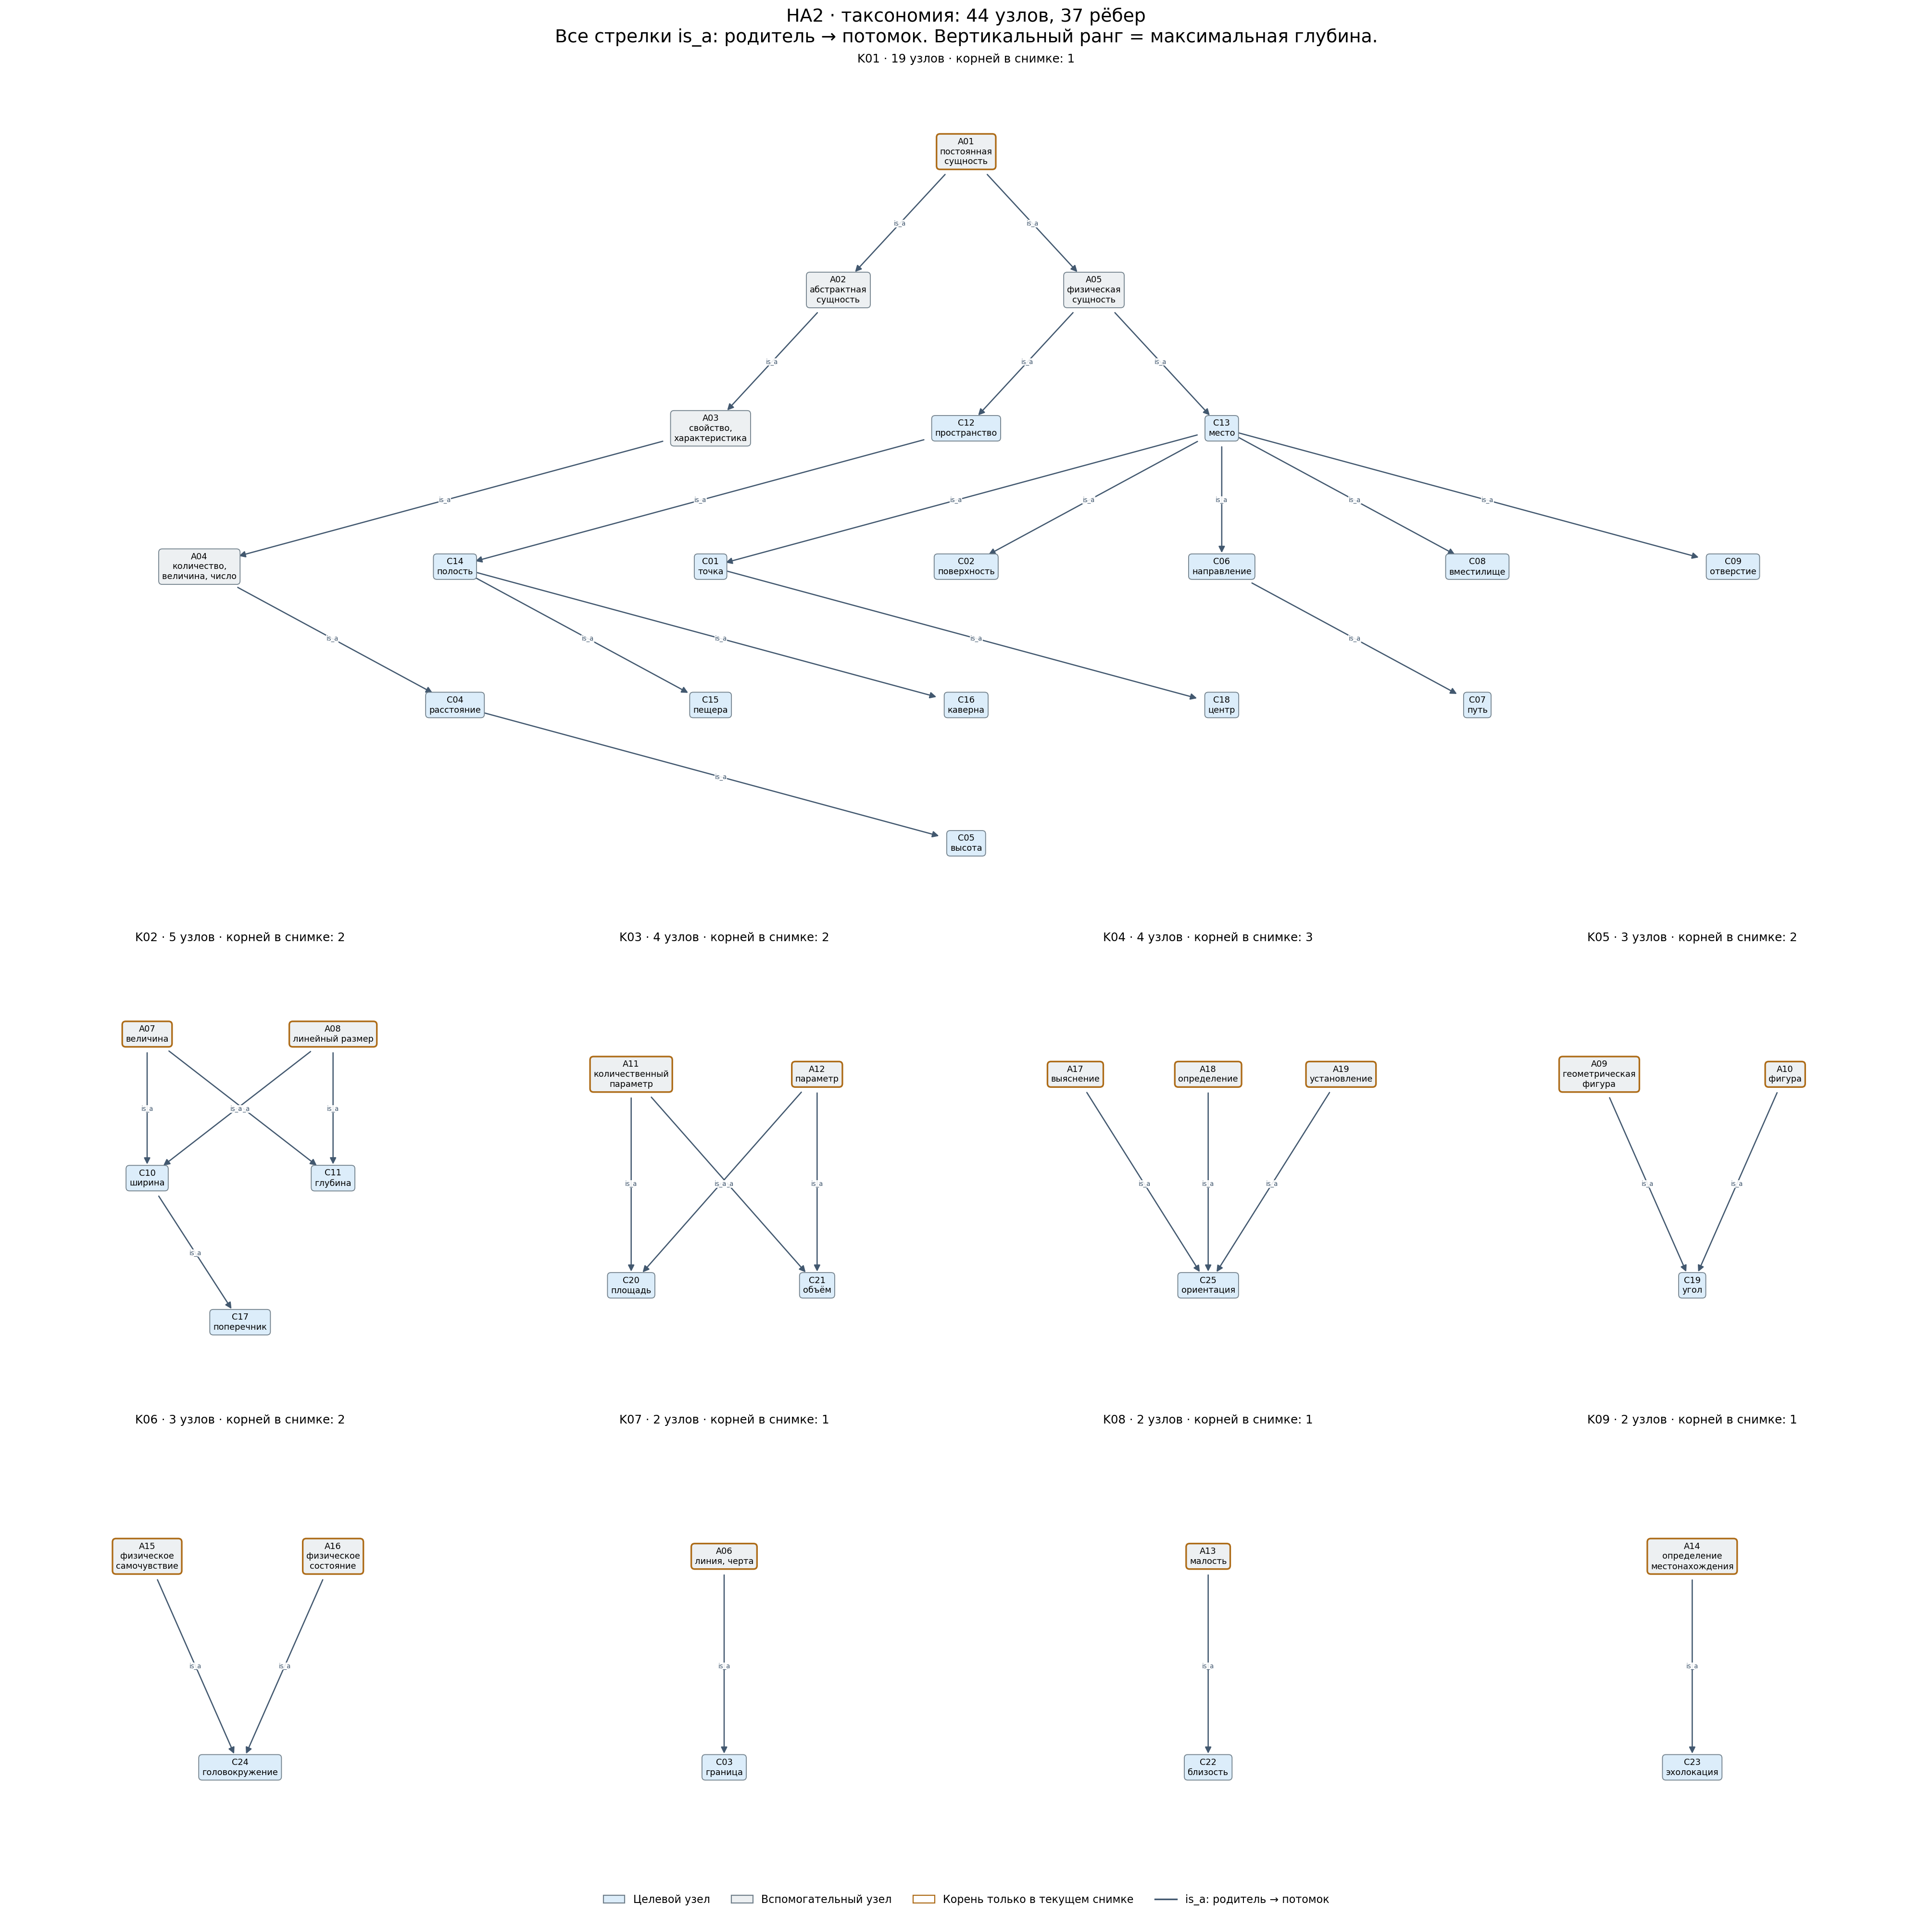

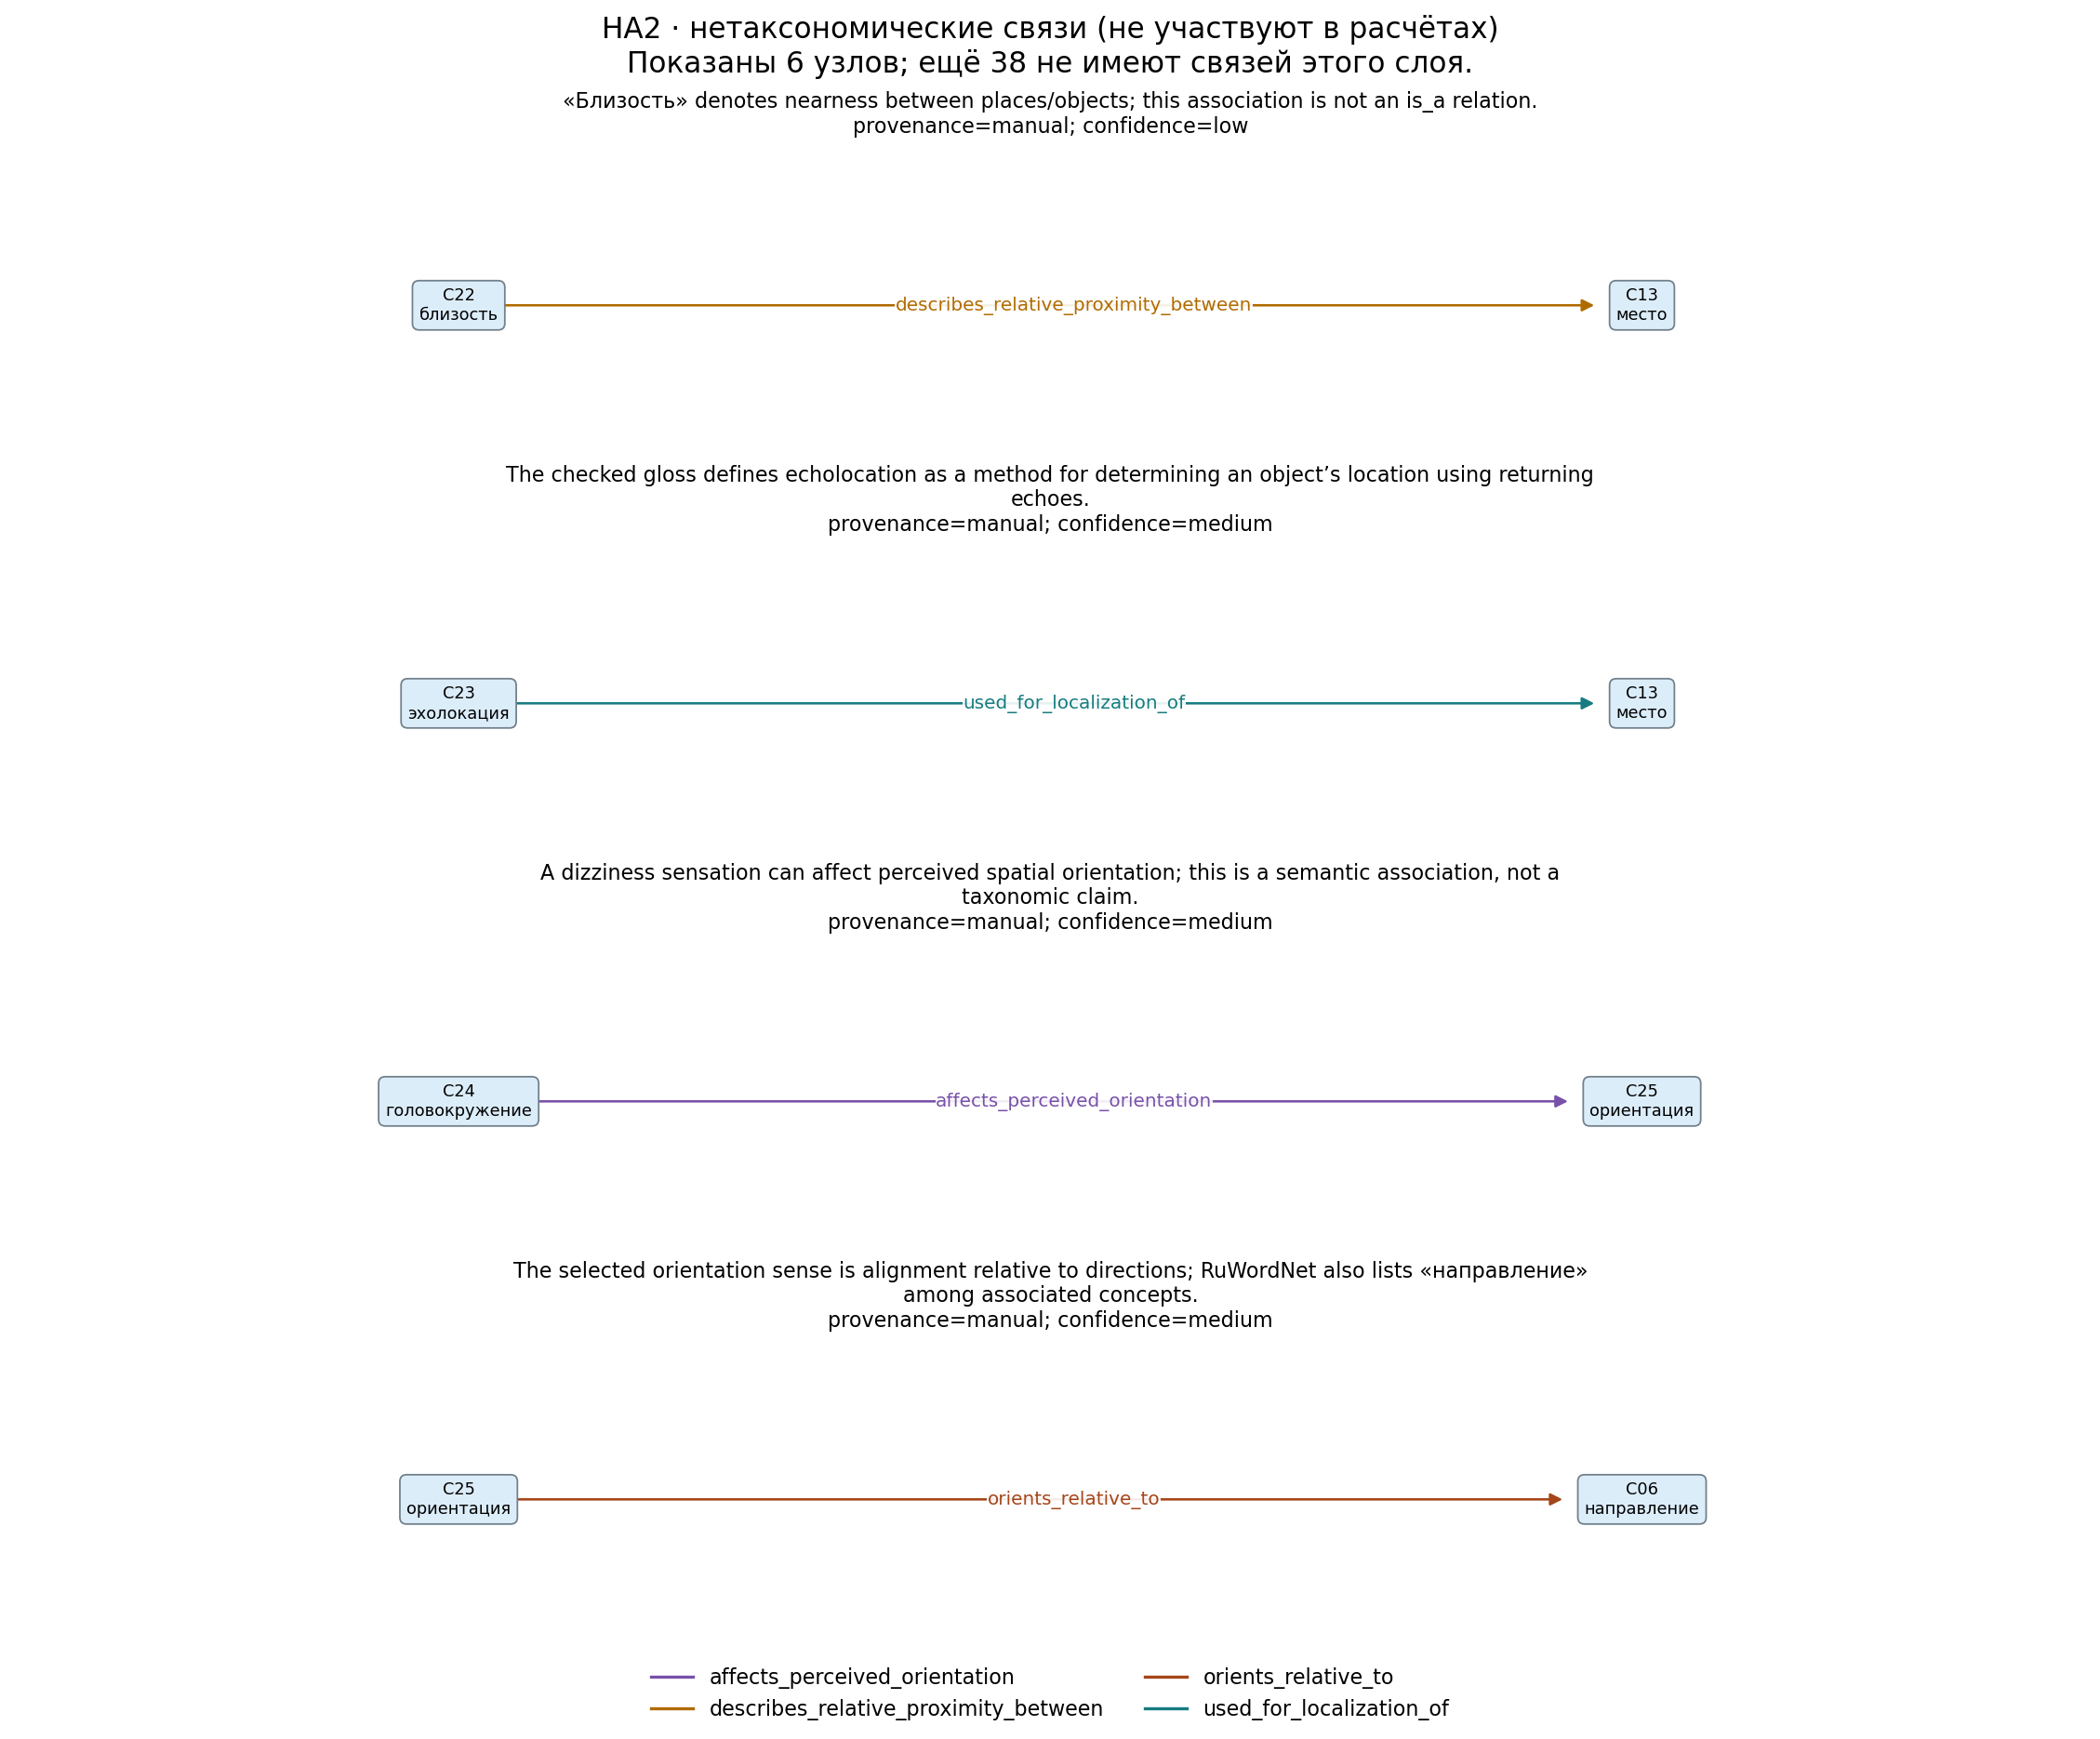

In [7]:
taxonomy_figure = draw_taxonomy(T)
relations_figure = draw_non_taxonomic(G)
save_figures(DATA_DIR, taxonomy_figure, relations_figure)
display(Image(filename=str(DATA_DIR / 'figures/taxonomy.png')))
display(Image(filename=str(DATA_DIR / 'figures/non_taxonomic.png')))
plt.close(taxonomy_figure)
plt.close(relations_figure)

In [8]:
validation = export_results(DATA_DIR, nodes, edges, G, T, specificity,
                            normalization_constants, direction_audit)
assert validation['all_nodes_scored']
assert validation['non_taxonomic_edges_used_for_specificity'] == 0
print({k: validation[k] for k in ('node_count', 'typed_edge_count', 'taxonomy_is_DAG',
                                'taxonomy_weak_components', 'all_nodes_scored')})
print('Baseline сохранён. Следующие ячейки обновляют HA1, perturbation и общий манифест.')

{'node_count': 44, 'typed_edge_count': 41, 'taxonomy_is_DAG': True, 'taxonomy_weak_components': 9, 'all_nodes_scored': True}
Baseline сохранён. Следующие ячейки обновляют HA1, perturbation и общий манифест.


## 6. Проверка покрытия HA1 — отдельная нормировка

C — сумма семи исходных признаков (каждый 0–2). S — кратчайшая глубина в baseline. Для HA1 обе метрики min–max-нормализованы **по 25 целевым понятиям**, не по всем узлам: C от 2 до 4, S от 1 до 5. Это не `S_depth=depth_min/5` из HA2. Значения ≥ 0.5 относятся к «+».

Исходная provisional-пометка `social=1` у «близости» не исправляется: отдельно проверяется консервативный вариант `social=0`. Минимум — три понятия на каждый квадрант. Выходы: `results/ha1_coverage/`.

Это проверка покрытия C×S, а не полный аудит всех требований HA1. Набор преимущественно пространственный; покрытие квадрантов не доказывает баланс модальностей.

In [9]:
coverage_report = run_coverage(DATA_DIR)
display(pd.DataFrame({name: coverage_report[name]['quadrant_counts']
                      for name in ('as_provided', 'closeness_social_0')}))
display(pd.read_csv(DATA_DIR / 'results/ha1_coverage/normalization.csv'))
display(pd.read_csv(DATA_DIR / 'results/ha1_coverage/quadrant_coverage.csv').round(4))
assert all(coverage_report[s]['quadrant_minimum_met'] for s in ('as_provided', 'closeness_social_0'))
print('PASS: все 25 понятий имеют S; минимум 3 на квадрант выполнен в обоих сценариях.')

,as_provided,closeness_social_0
C+ S+,5,5
C+ S-,6,5
C- S+,7,7
C- S-,7,8


,scenario,target_count,usable_S_count,C_min,C_max,S_min,S_max,C_threshold,S_threshold,minimum_per_quadrant
0,as_provided,25,25,2,4,1,5,0.5,0.5,3
1,closeness_social_0,25,25,2,4,1,5,0.5,0.5,3


,node_id,term,visual,auditory,tactile,motor,proprioceptive,interoceptive,social,C_raw,S_raw,C_norm,S_norm,quadrant,S_missing_reason
0,C01,точка,2,0,0,0,0,0,0,2,3,0.0,0.50,C- S+,NaN
1,C02,поверхность,1,0,1,0,0,0,0,2,3,0.0,0.50,C- S+,NaN
2,C03,граница,2,0,1,0,0,0,0,3,1,0.5,0.00,C+ S-,NaN
3,C04,расстояние,1,0,0,0,1,0,0,2,4,0.0,0.75,C- S+,NaN
4,C05,высота,2,0,0,0,1,0,0,3,5,0.5,1.00,C+ S+,NaN
5,C06,направление,2,0,0,1,1,0,0,4,3,1.0,0.50,C+ S+,NaN
6,C07,путь,1,0,0,1,1,0,0,3,4,0.5,0.75,C+ S+,NaN
7,C08,вместилище,2,0,1,0,1,0,0,4,3,1.0,0.50,C+ S+,NaN
8,C09,отверстие,2,0,1,0,0,0,0,3,3,0.5,0.50,C+ S+,NaN
9,C10,ширина,2,0,1,0,1,0,0,4,1,1.0,0.00,C+ S-,NaN


PASS: все 25 понятий имеют S; минимум 3 на квадрант выполнен в обоих сценариях.


## 7. Новый последовательный perturbation

**Baseline → +3 ребра → −3 ребра из состояния после добавлений.** Это не два независимых изменения baseline. Удаляются три исходных ребра, а не только что добавленные.

Новый baseline сохраняется побайтово в `results/perturbation/baseline_*`. Все 44 узла остаются во всех состояниях. Добавления — manual-гипотезы: количество → линейный размер, транзитивный shortcut физическая сущность → полость и нетаксономическое эхолокация → расстояние (`estimates`). Удаляются место → точка, полость → каверна, расстояние → высота. Это не исправление таксономии команды.

ID проверяются вместе с названиями и source_id; проверяются DAG и предусловия. Обе HA2-оценки используют те же формулы и глобальную область, но знаменатели пересчитываются для каждого состояния. Нетаксономический контроль выполняется во всех состояниях.

Строгий порог — `|Δ| > 0.1`, не `≥`; защита от ошибки float на границе — `1e-12`. Перед отбором разности не округляются. В `deltas.csv` отдельно сохранены структурная часть при прежнем знаменателе и нормировочная часть. Изоляты имеют только механические баллы, не доказанную лексическую специфичность.

Обе версии удаляют место -> точка и расстояние -> высота. В таблице ниже after_remove дополнительно удаляет полость -> каверна, slide30_remove удаляет добавленное физическая сущность -> полость. У S_depth знаменатель max_depth_shortest, у обоих концов диапазона max_depth_longest.

In [10]:
perturbation_report = run_perturbation(DATA_DIR)
EXPERIMENT = DATA_DIR / 'results/perturbation'
scenario = json.loads((EXPERIMENT / 'scenario.json').read_text())
display(pd.concat([pd.DataFrame(scenario['additions']).assign(action='+'),
                   pd.DataFrame(scenario['removals']).assign(action='−')], ignore_index=True)
        [['action', 'source', 'relation', 'target', 'justification']])
display(pd.read_csv(EXPERIMENT / 'structure.csv').fillna(''))
display(pd.concat([pd.read_csv(EXPERIMENT / f'{s}_normalization.csv').assign(stage=s)
                   for s in ('baseline', 'after_add', 'after_remove')], ignore_index=True).round(6))
display(pd.read_csv(EXPERIMENT / 'change_summary.csv'))
changes = pd.read_csv(EXPERIMENT / 'changes_gt_0_1.csv', dtype={'is_target': str})
display(changes.loc[changes.is_target.eq('TRUE')].round(6))
routes = []
for state in ('baseline', 'after_add', 'after_remove'):
    scores = pd.read_csv(EXPERIMENT / f'{state}_specificity.csv', keep_default_na=False)
    routes.append(scores.loc[(scores.parent_count > 1) | (scores.depth_min != scores.depth_max)].assign(state=state))
display(pd.concat(routes)[['state', 'node_id', 'label', 'parent_ids', 'root_ids',
                           'depth_min', 'depth_max', 'S_depth_range_min', 'S_depth_range_max']].round(4))
print('Сохранены все три состояния, 264 разности и строгий список |Δ| > 0.1.')

# Compare the same graph before branching into the two deletion scenarios.
from role4_slide30 import run as slide30
slide30(DATA_DIR)
audit = pd.read_csv(DATA_DIR / 'results/slide30/coverage_audit.csv')
display(audit[audit.node_id.eq('C14')][['stage','depth_min','depth_max','S_depth',
    'max_depth_shortest','S_depth_range_min','S_depth_range_max','max_depth_longest']])
display(audit[audit.stage.str.contains('remove') & ~audit.reachable_from_pre_deletion_roots][
    ['stage','label','coverage_fixed_roots','S_depth','S_breadth']])
display(audit[audit.node_id.eq('C04')][['stage','depth_min','S_depth','S_depth_fixed_denominator']])


,action,source,relation,target,justification
0,+,A04,is_a,A08,Экспериментальная manual-гипотеза: линейный ра...
1,+,A05,is_a,C14,Экспериментальный транзитивный shortcut: в bas...
2,+,C23,estimates,C04,Экспериментальная manual-ассоциация: по задерж...
3,−,C13,is_a,C01,Абляция внутреннего ребра место → точка: отдел...
4,−,C14,is_a,C16,Абляция ребра к листу каверна: проверяет изоля...
5,−,C04,is_a,C05,Абляция ребра к самому глубокому листу высота:...


,stage,node_count,typed_edges,taxonomy_edges,components,roots,isolates,isolate_ids,multiple_parents,unequal_depth_nodes
0,baseline,44,41,37,9,15,0,,7,0
1,after_add,44,44,39,8,14,0,,8,6
2,after_remove,44,41,36,11,17,2,C05;C16,8,5


,scope,node_count,edge_count,max_depth_shortest,max_depth_longest,max_descendants,breadth_log_denominator,slide28_raw_min,slide28_raw_max,min_normalization_nodes,normalization_status,stage
0,global,44,37,5,5,18,2.944439,-3.091042,1.215810,10,ok,baseline
1,POS:NOUN,44,37,5,5,18,2.944439,-3.091042,1.215810,10,ok,baseline
2,global,44,39,5,6,22,3.135494,-3.091042,1.602105,10,ok,after_add
3,POS:NOUN,44,39,5,6,22,3.135494,-3.091042,1.602105,10,ok,after_add
4,global,44,36,4,6,18,2.944439,-3.784190,1.602105,10,ok,after_remove
5,POS:NOUN,44,36,4,6,18,2.944439,-3.784190,1.602105,10,ok,after_remove


,from,to,metric,all_nodes_exceeding,target_nodes_exceeding
0,baseline,after_add,S_depth,4,3
1,baseline,after_add,S_breadth,3,0
2,baseline,after_remove,S_depth,12,10
3,baseline,after_remove,S_breadth,5,2
4,after_add,after_remove,S_depth,13,11
5,after_add,after_remove,S_breadth,2,2


,node_id,label,is_target,from,to,metric,S_from,S_to,delta,abs_delta,raw_from,raw_to,denominator_from,denominator_to,delta_structure_from_scale,delta_normalization,exceeds_threshold
1,C14,полость,TRUE,baseline,after_add,S_depth,0.600000,0.400000,-0.200000,0.200000,3,2,5.000000,5.000000,-0.200000,0.000000,True
2,C15,пещера,TRUE,baseline,after_add,S_depth,0.800000,0.600000,-0.200000,0.200000,4,3,5.000000,5.000000,-0.200000,0.000000,True
3,C16,каверна,TRUE,baseline,after_add,S_depth,0.800000,0.600000,-0.200000,0.200000,4,3,5.000000,5.000000,-0.200000,0.000000,True
9,C01,точка,TRUE,baseline,after_remove,S_depth,0.600000,0.000000,-0.600000,0.600000,3,0,5.000000,4.000000,-0.600000,0.000000,True
10,C02,поверхность,TRUE,baseline,after_remove,S_depth,0.600000,0.750000,0.150000,0.150000,3,3,5.000000,4.000000,0.000000,0.150000,True
11,C04,расстояние,TRUE,baseline,after_remove,S_depth,0.800000,1.000000,0.200000,0.200000,4,4,5.000000,4.000000,0.000000,0.200000,True
12,C05,высота,TRUE,baseline,after_remove,S_depth,1.000000,0.000000,-1.000000,1.000000,5,0,5.000000,4.000000,-1.000000,0.000000,True
13,C06,направление,TRUE,baseline,after_remove,S_depth,0.600000,0.750000,0.150000,0.150000,3,3,5.000000,4.000000,0.000000,0.150000,True
14,C07,путь,TRUE,baseline,after_remove,S_depth,0.800000,1.000000,0.200000,0.200000,4,4,5.000000,4.000000,0.000000,0.200000,True
15,C08,вместилище,TRUE,baseline,after_remove,S_depth,0.600000,0.750000,0.150000,0.150000,3,3,5.000000,4.000000,0.000000,0.150000,True


,state,node_id,label,parent_ids,root_ids,depth_min,depth_max,S_depth_range_min,S_depth_range_max
28,baseline,C10,ширина,A07;A08,A07;A08,1,1,0.2000,0.2000
29,baseline,C11,глубина,A07;A08,A07;A08,1,1,0.2000,0.2000
37,baseline,C19,угол,A09;A10,A09;A10,1,1,0.2000,0.2000
38,baseline,C20,площадь,A11;A12,A11;A12,1,1,0.2000,0.2000
39,baseline,C21,объём,A11;A12,A11;A12,1,1,0.2000,0.2000
42,baseline,C24,головокружение,A15;A16,A15;A16,1,1,0.2000,0.2000
43,baseline,C25,ориентация,A17;A18;A19,A17;A18;A19,1,1,0.2000,0.2000
28,after_add,C10,ширина,A07;A08,A01;A07,1,5,0.1667,0.8333
29,after_add,C11,глубина,A07;A08,A01;A07,1,5,0.1667,0.8333
32,after_add,C14,полость,A05;C12,A01,2,3,0.3333,0.5000


Сохранены все три состояния, 264 разности и строгий список |Δ| > 0.1.


,stage,depth_min,depth_max,S_depth,max_depth_shortest,S_depth_range_min,S_depth_range_max,max_depth_longest
32,baseline,3,3,0.60,5,0.600000,0.6,5
76,after_add,2,3,0.40,5,0.333333,0.5,6
120,after_remove,2,3,0.50,4,0.333333,0.5,6
164,slide30_remove,3,3,0.75,4,0.500000,0.5,6


,stage,label,coverage_fixed_roots,S_depth,S_breadth
107,after_remove,точка,out_of_coverage,0.00,0.764591
111,after_remove,высота,out_of_coverage,0.00,1.000000
122,after_remove,каверна,out_of_coverage,0.00,1.000000
124,after_remove,центр,out_of_coverage,0.25,1.000000
151,slide30_remove,точка,out_of_coverage,0.00,0.768622
155,slide30_remove,высота,out_of_coverage,0.00,1.000000
168,slide30_remove,центр,out_of_coverage,0.25,1.000000


,stage,depth_min,S_depth,S_depth_fixed_denominator
22,baseline,4,0.8,0.8
66,after_add,4,0.8,0.8
110,after_remove,4,1.0,0.8
154,slide30_remove,4,1.0,0.8


## 8. Изображения нового комплекта

Все графы рисуются заново из актуальных JSON. Для каждого экспериментального состояния показаны таксономия всех узлов и отдельный нетаксономический слой; названия состояний включены в заголовки. Вертикальный ранг — длиннейший путь. График изменений содержит оба состояния относительно baseline; штриховые линии — ±0.1. HA1 показана отдельно, без подмены её нормировки метриками HA2.

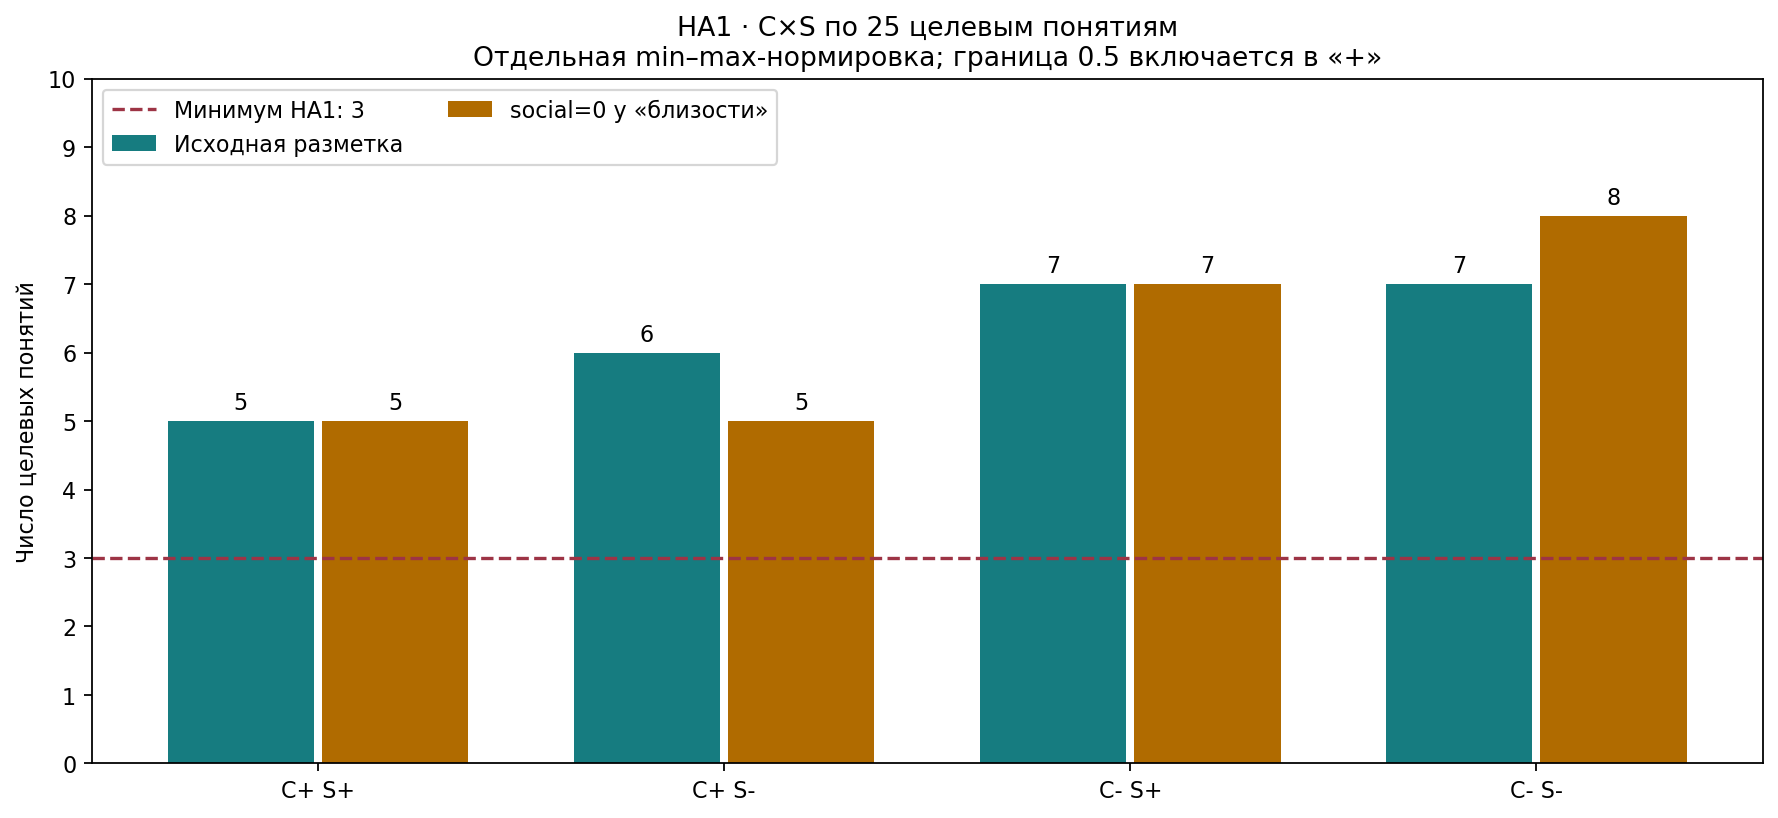

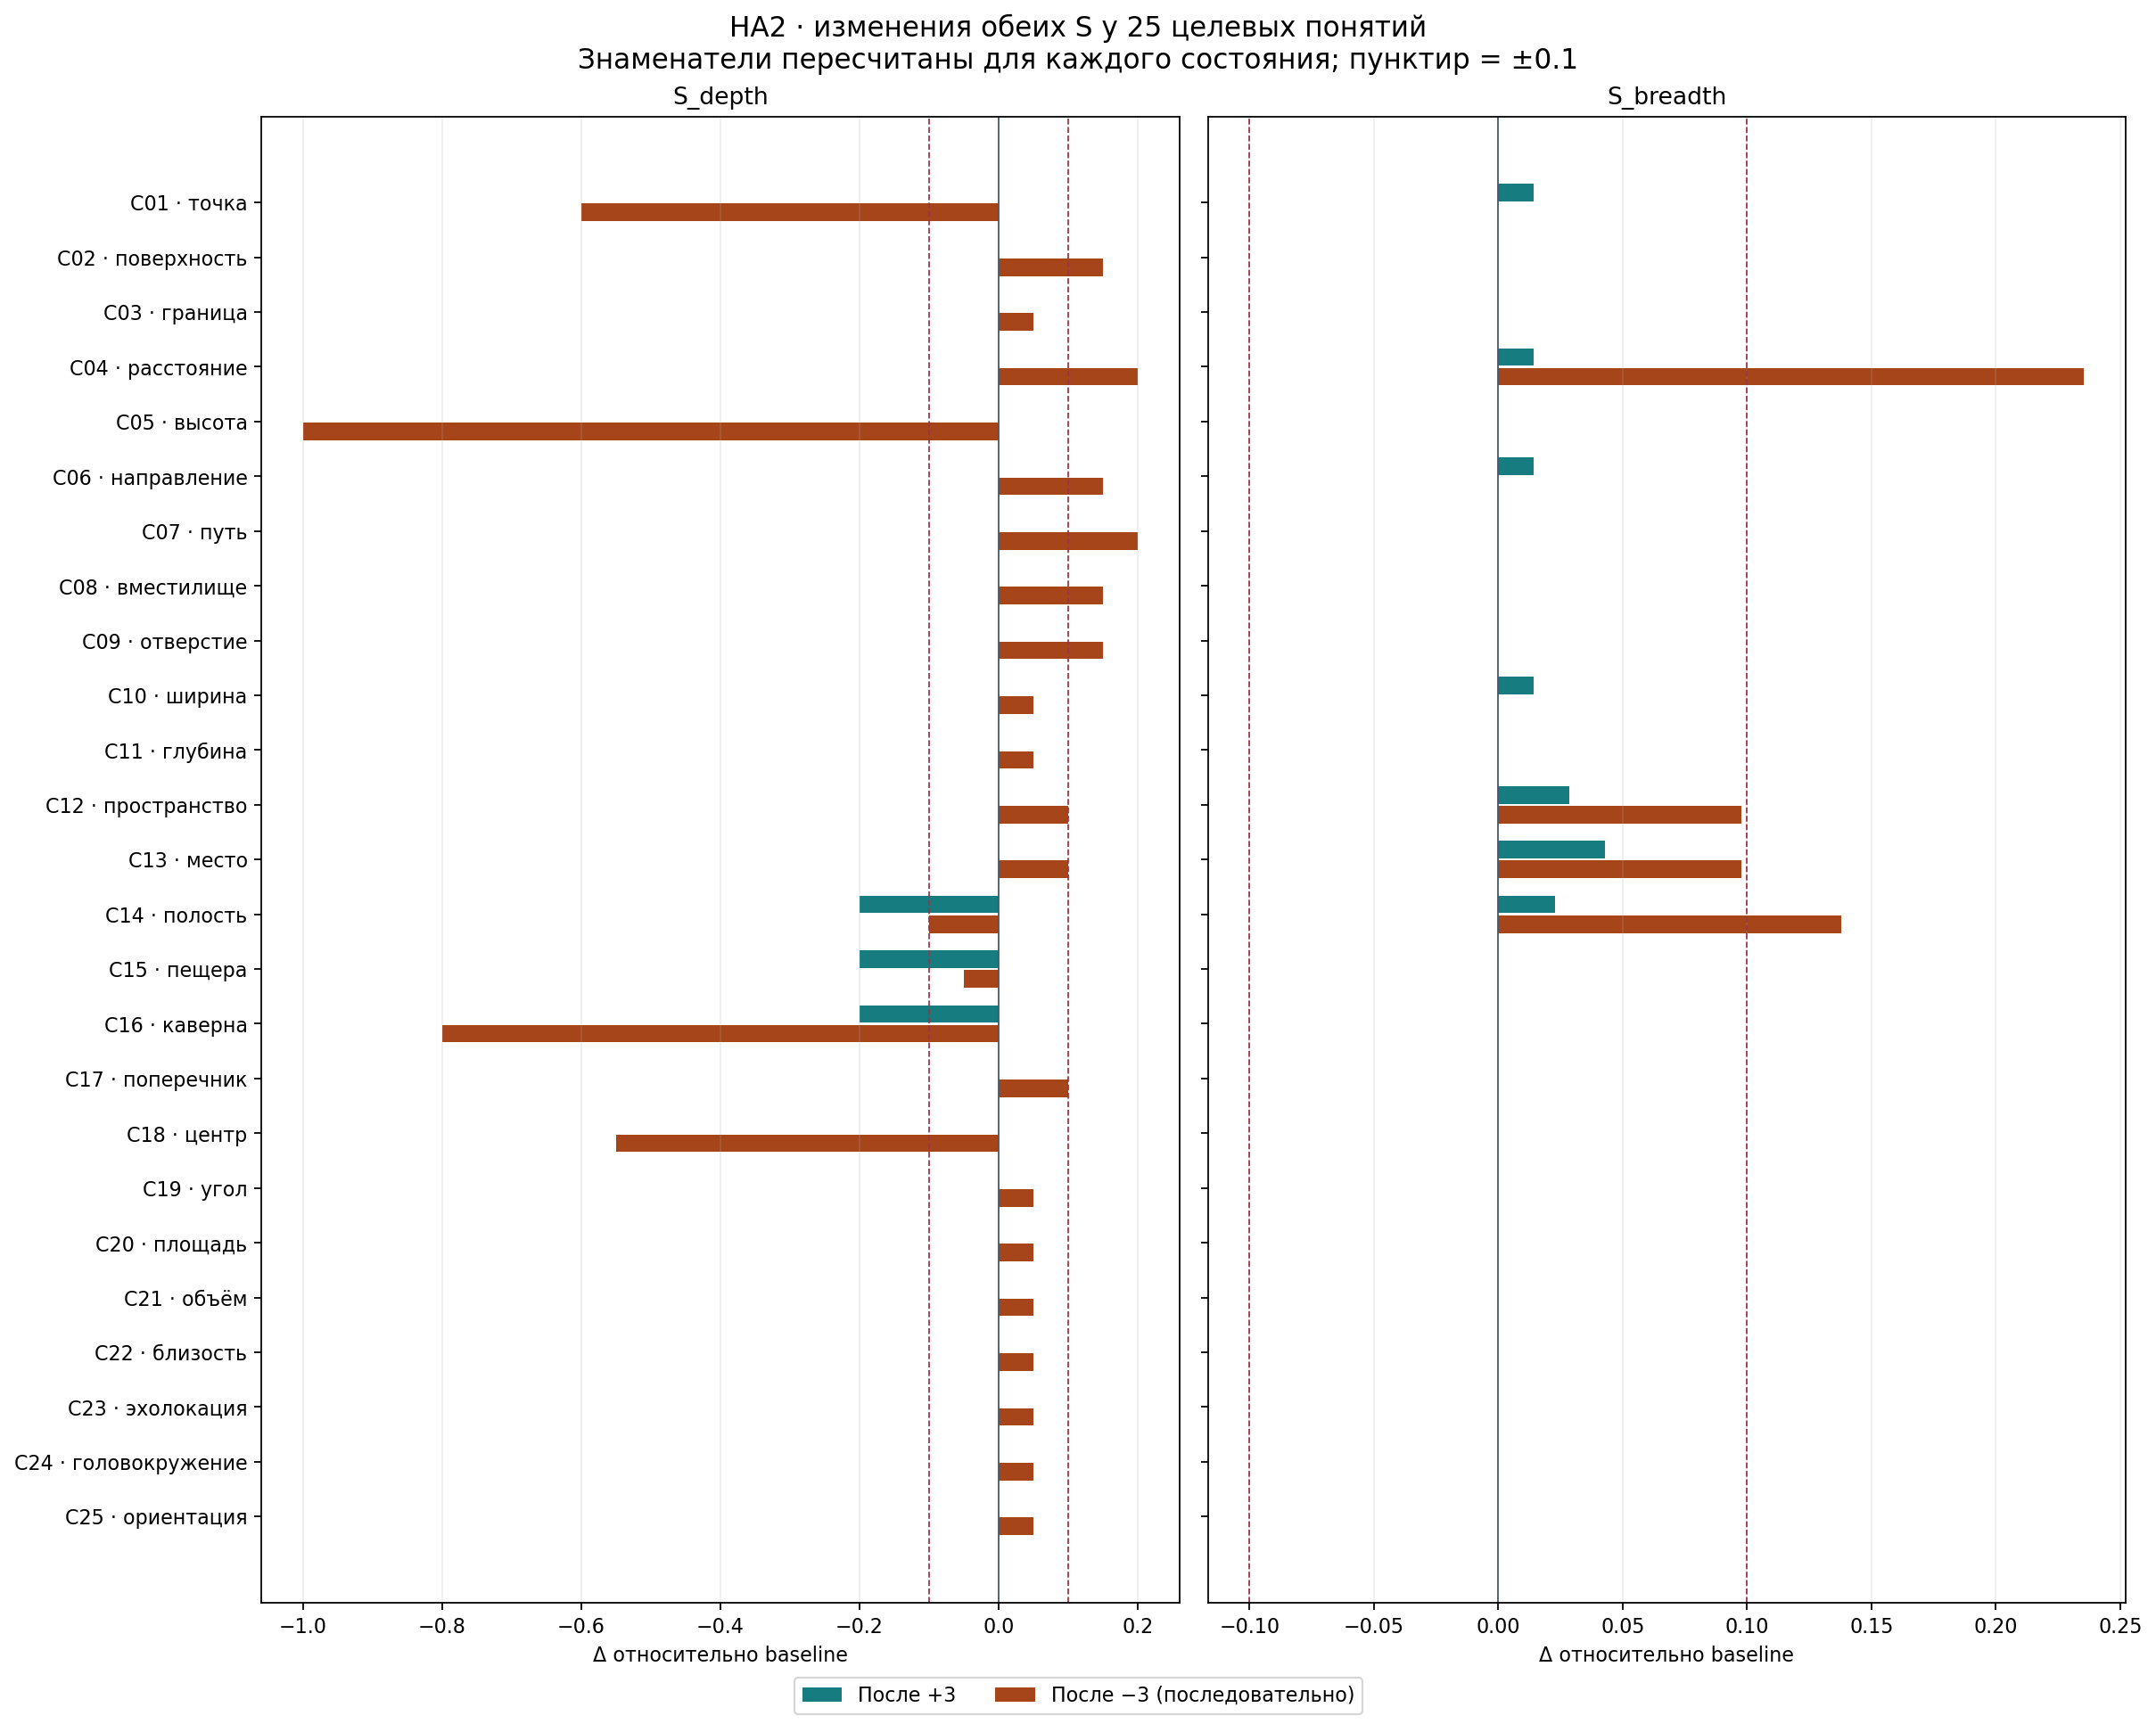

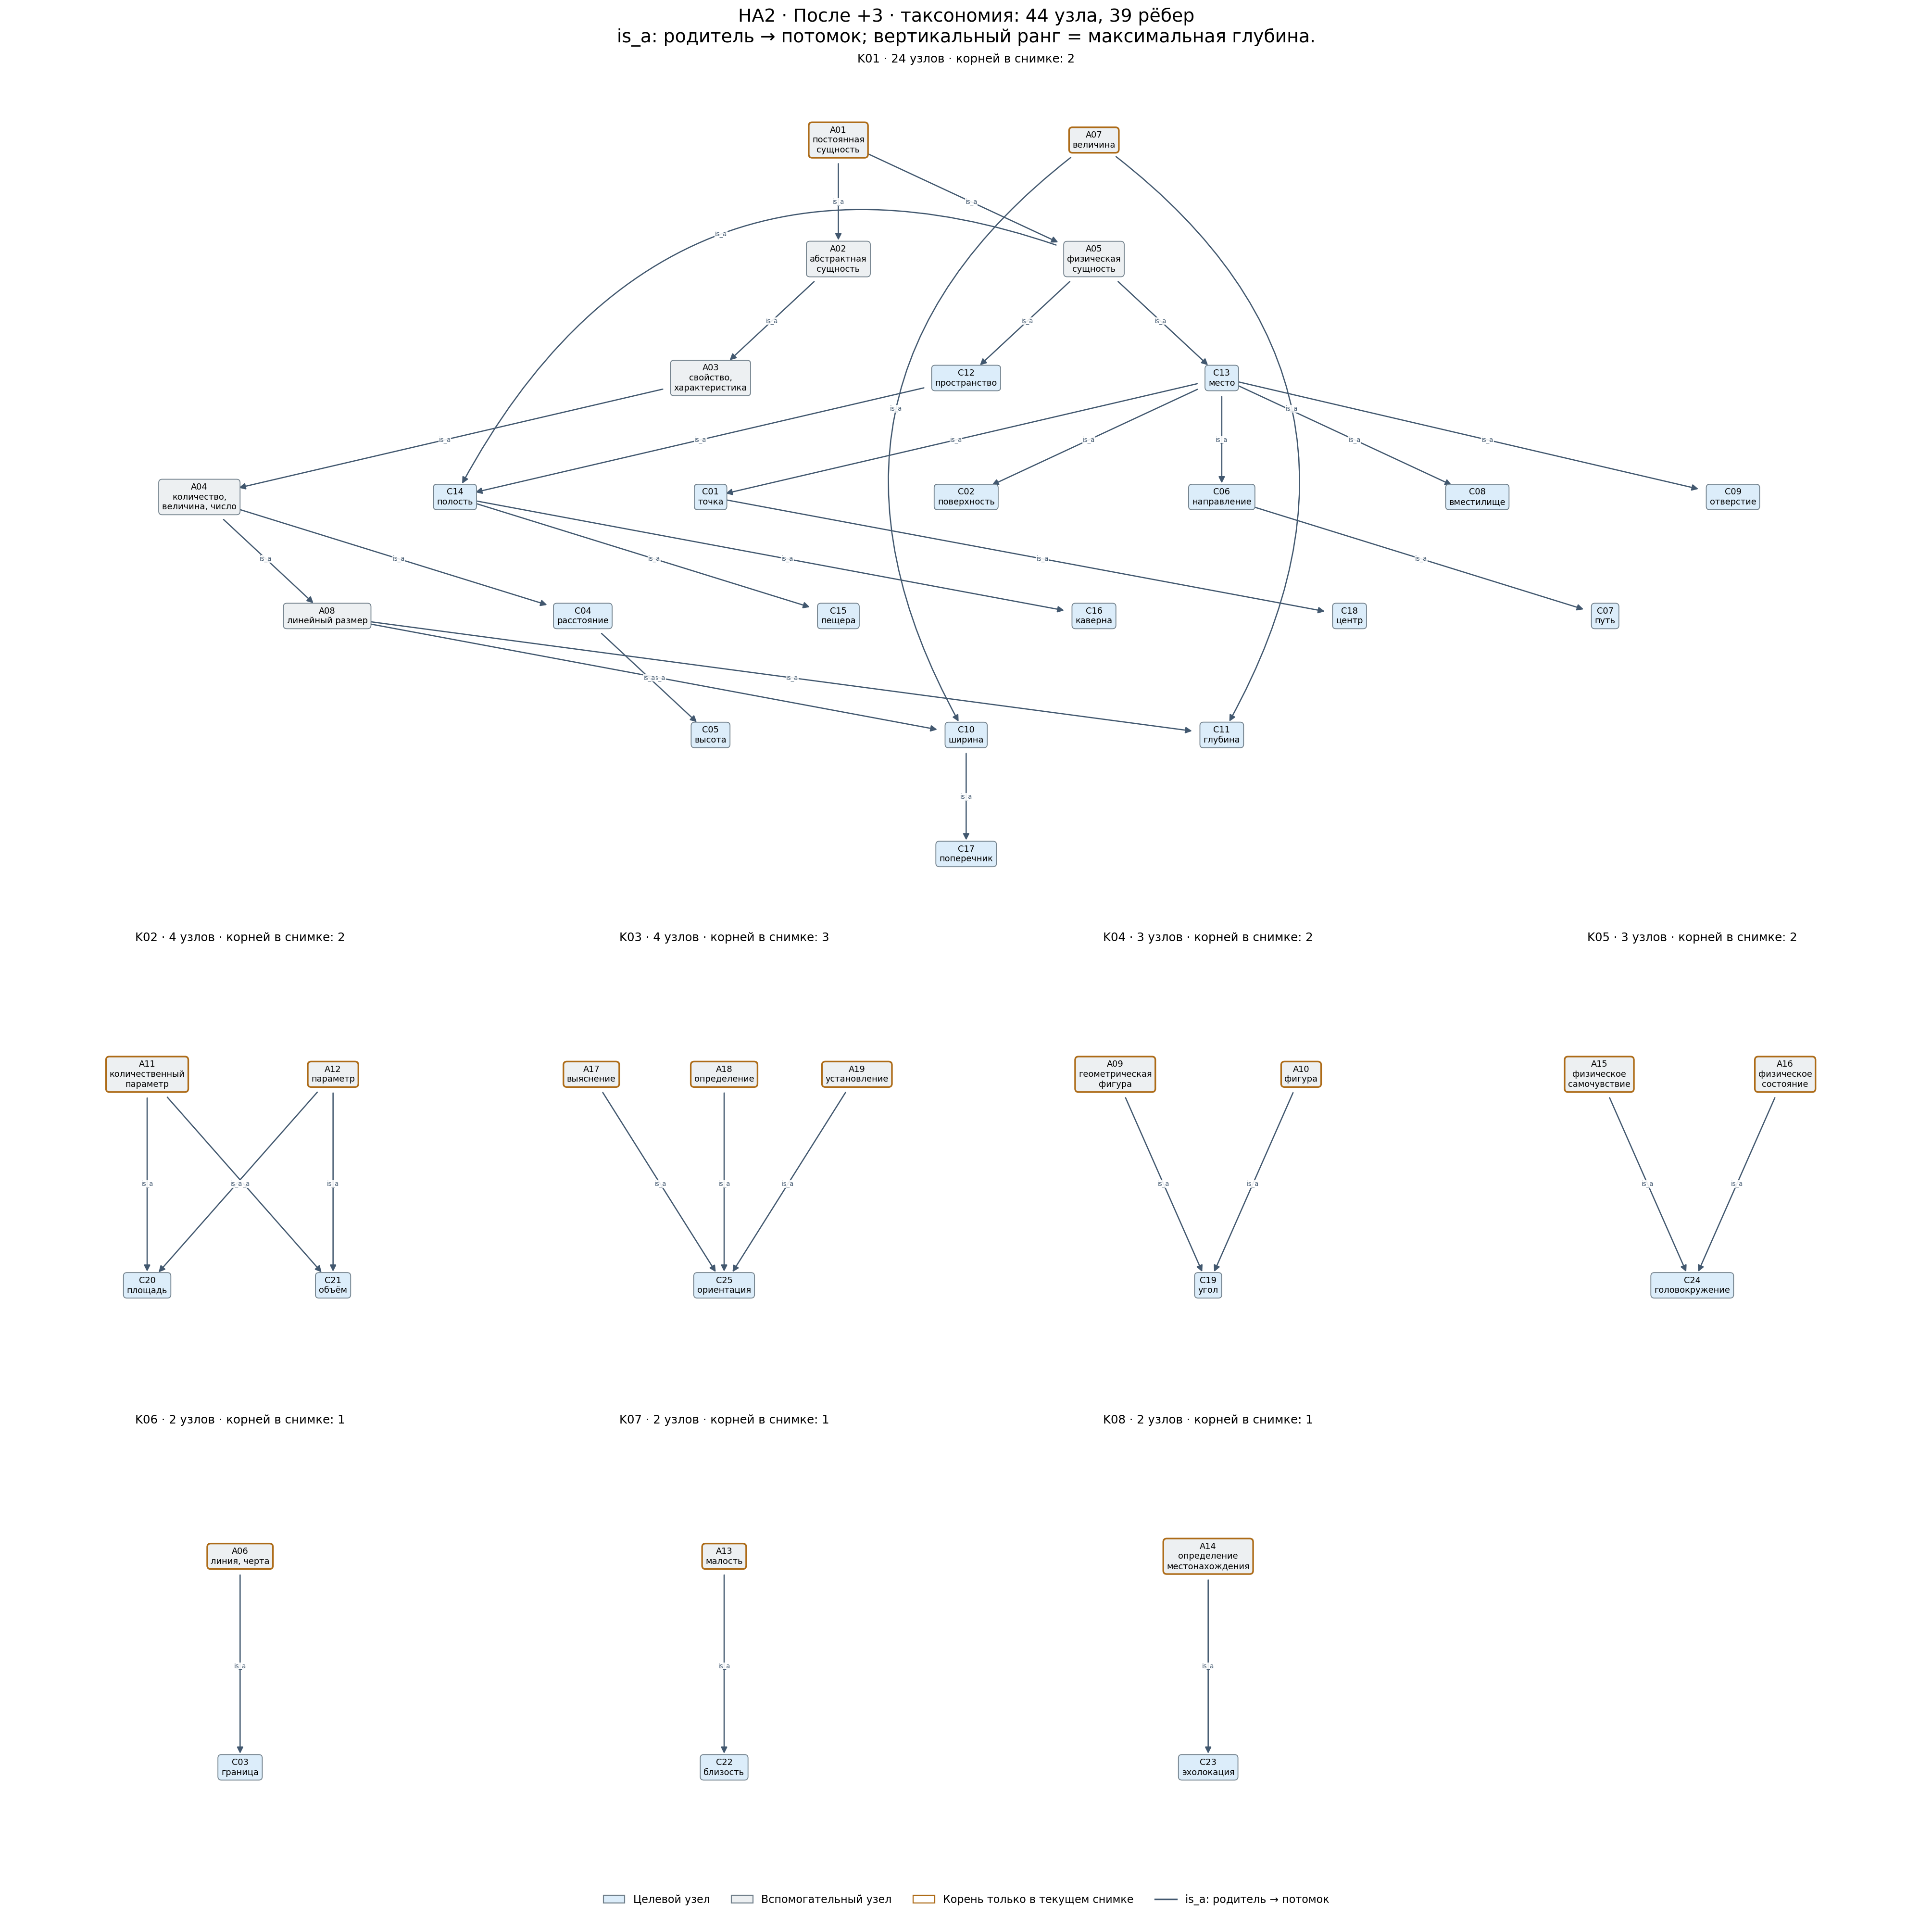

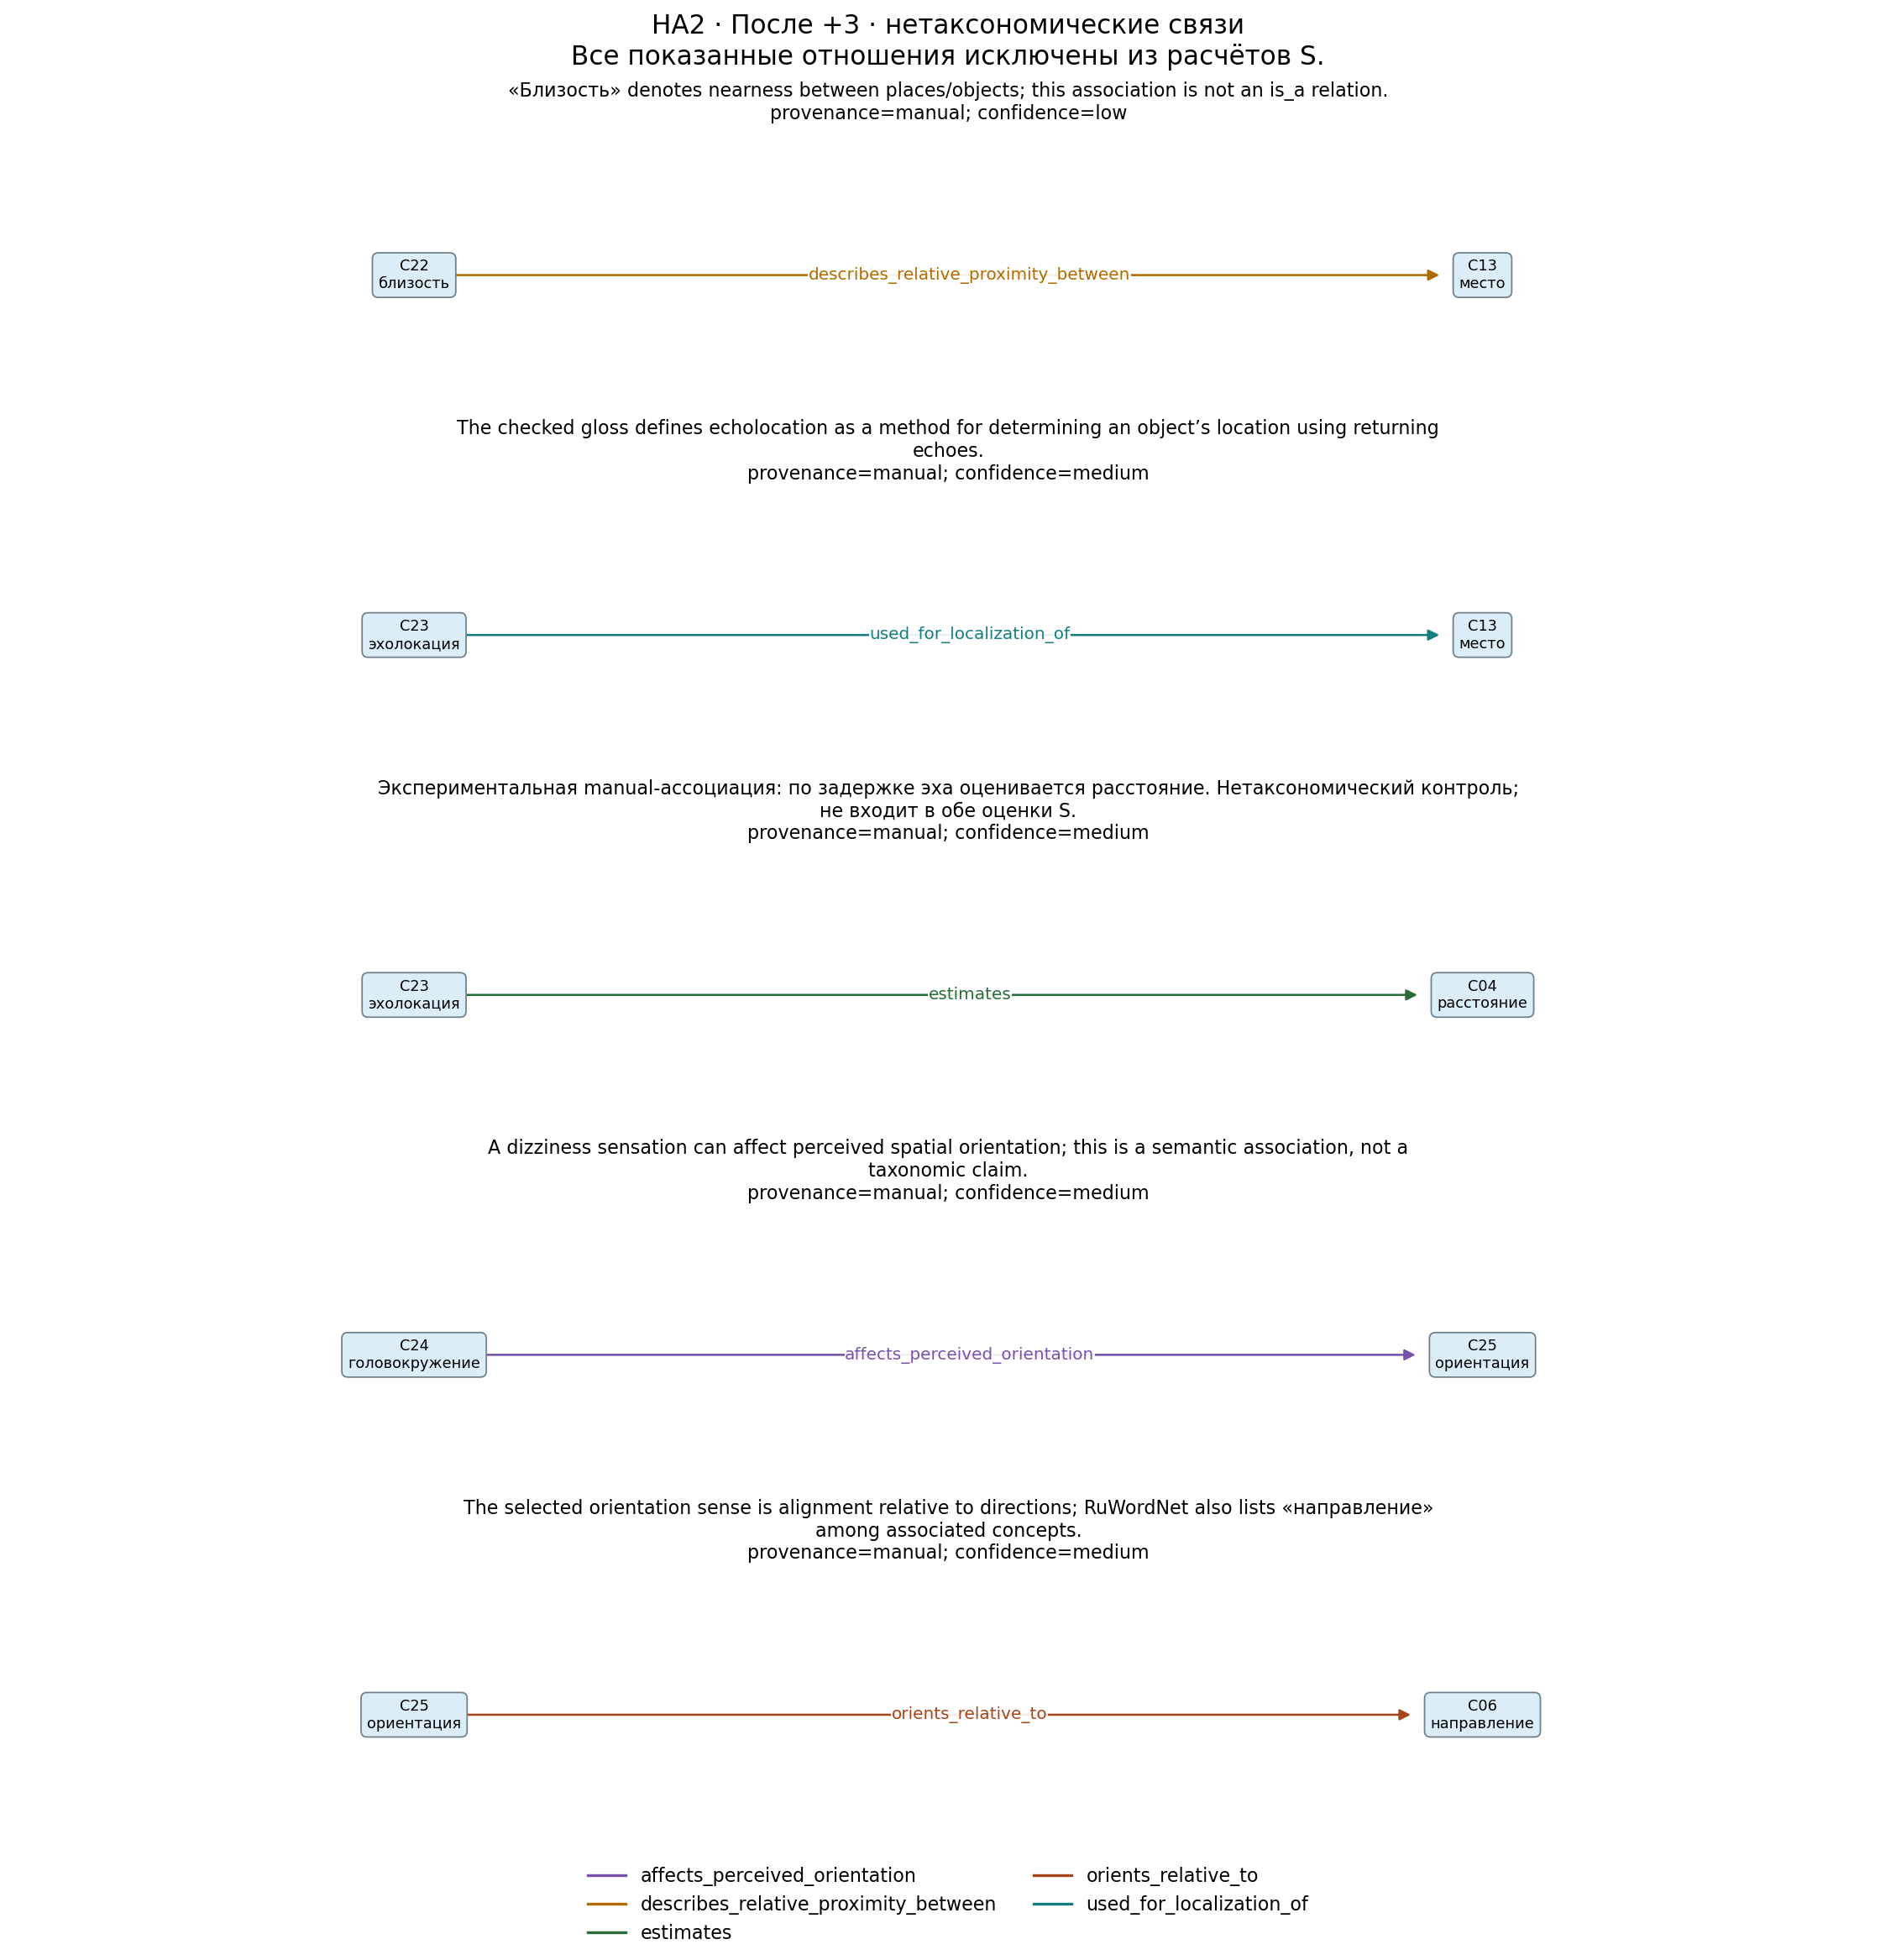

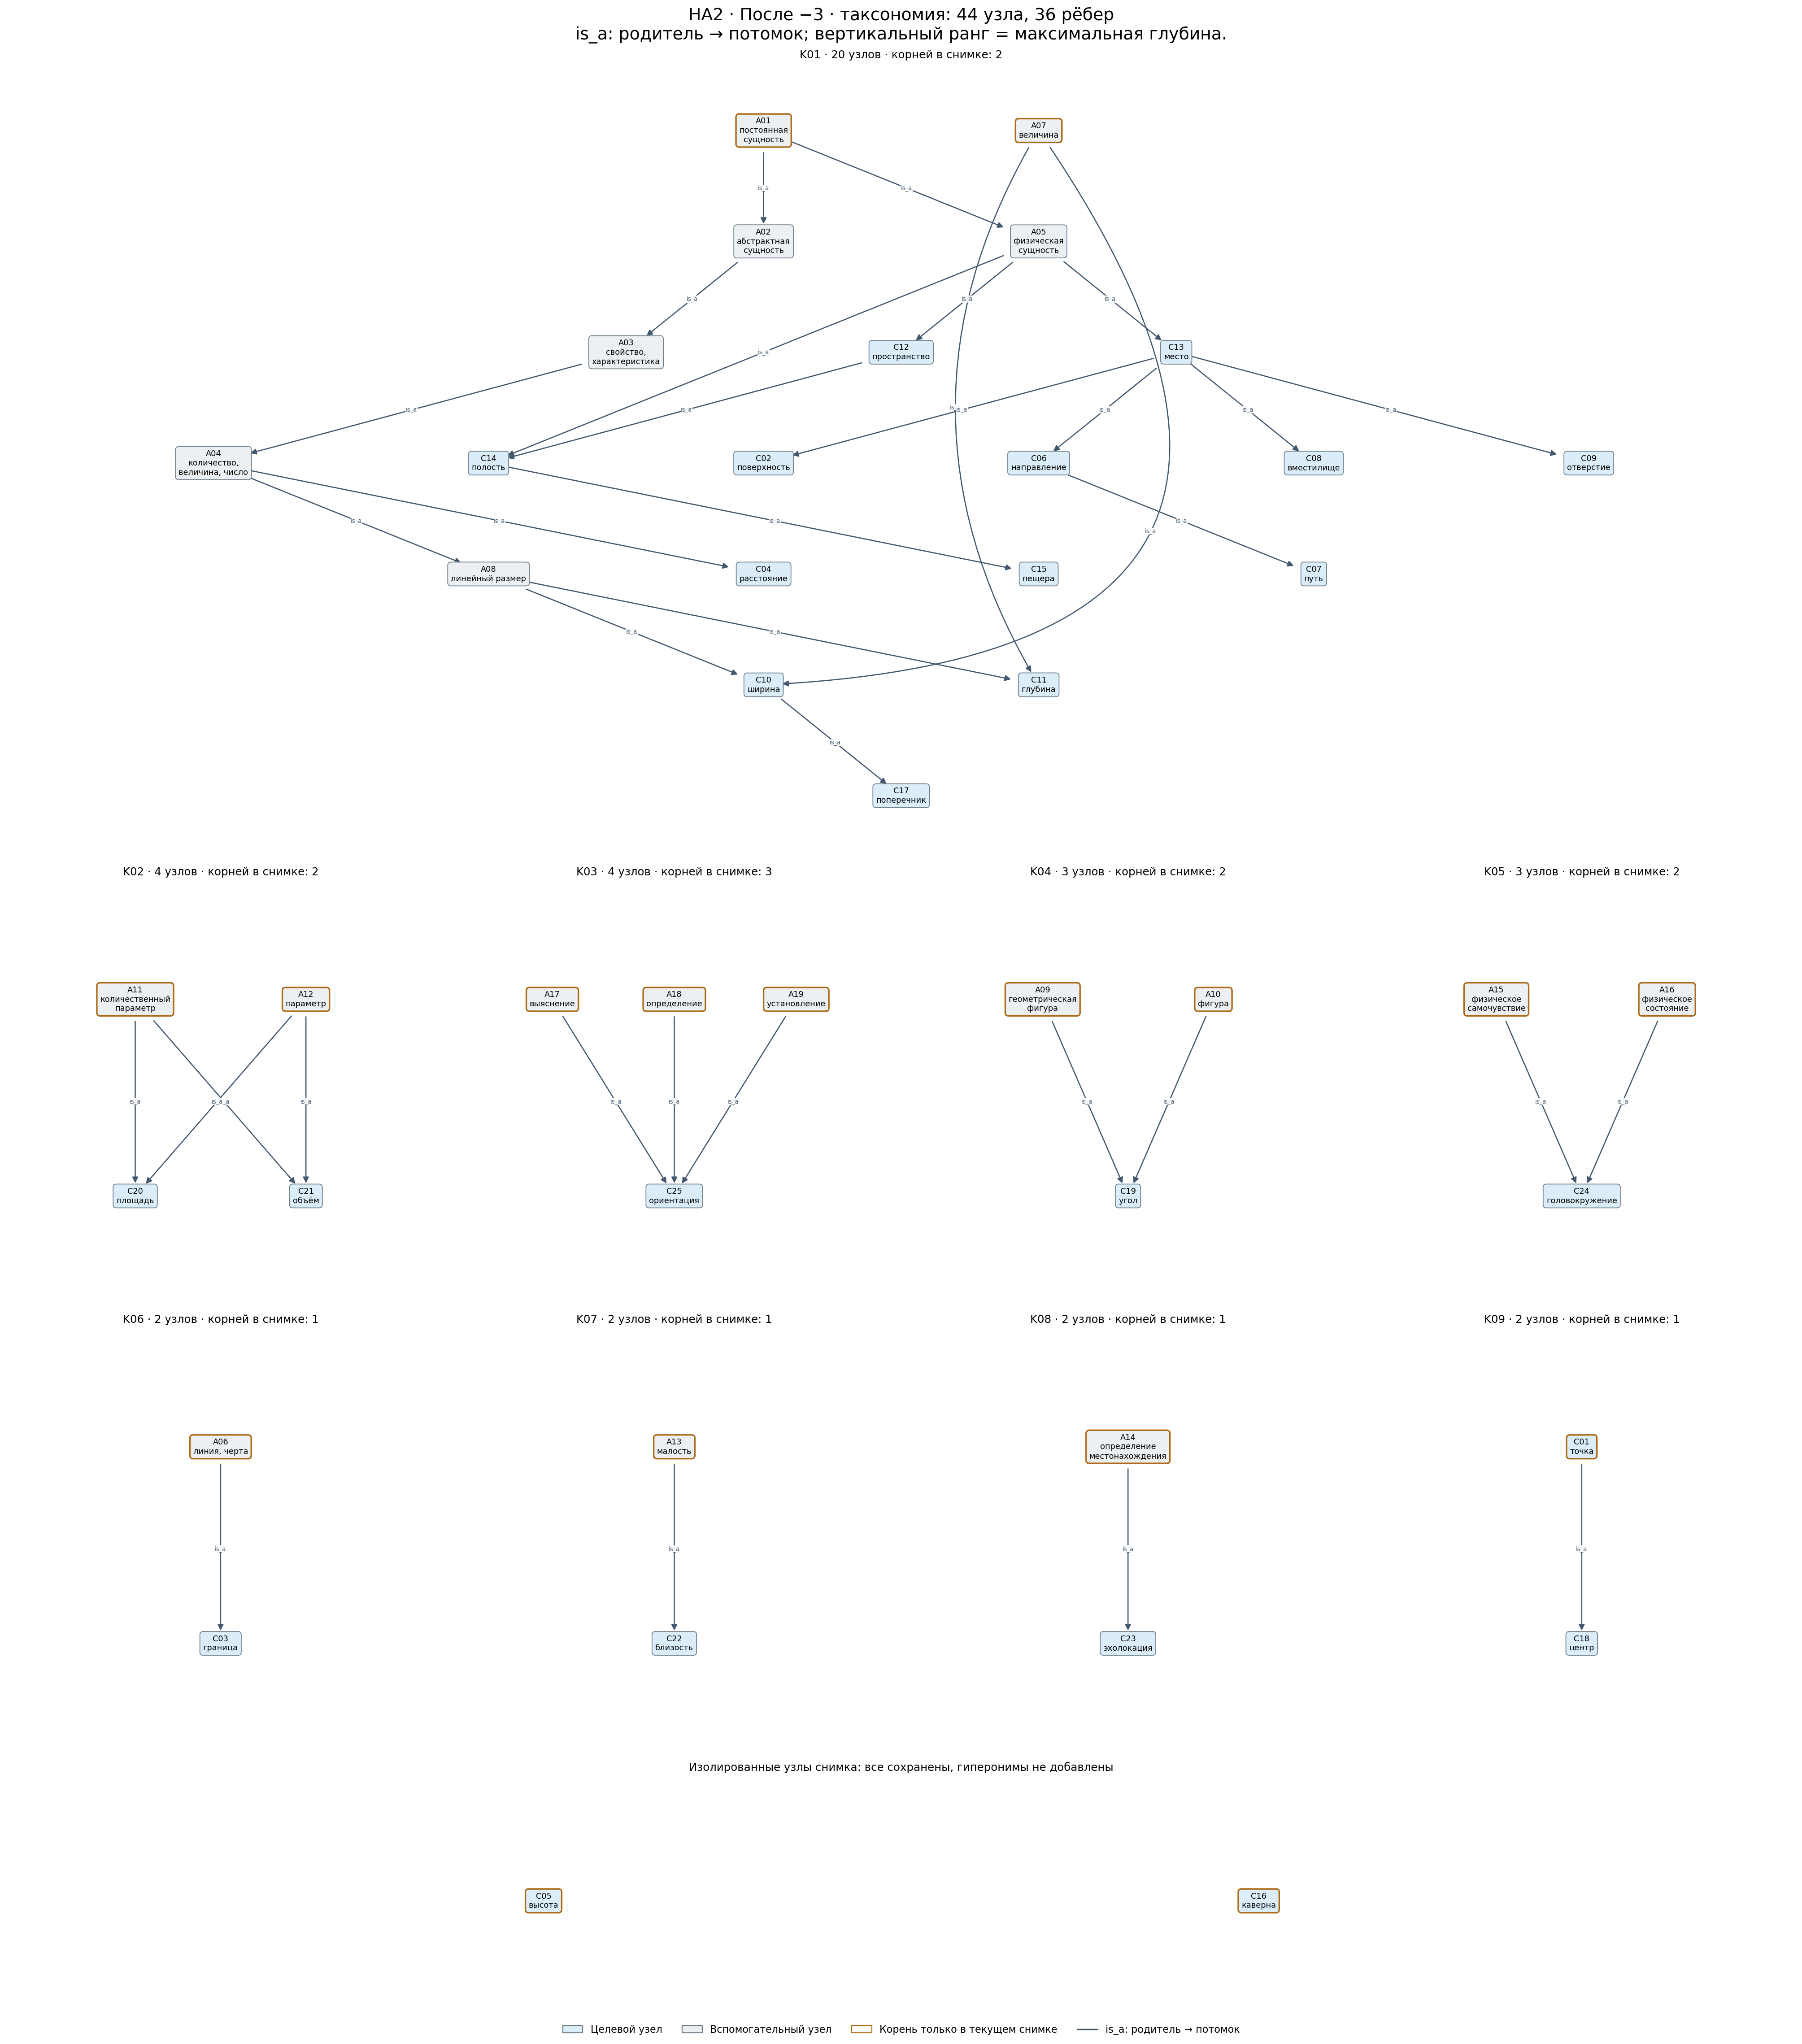

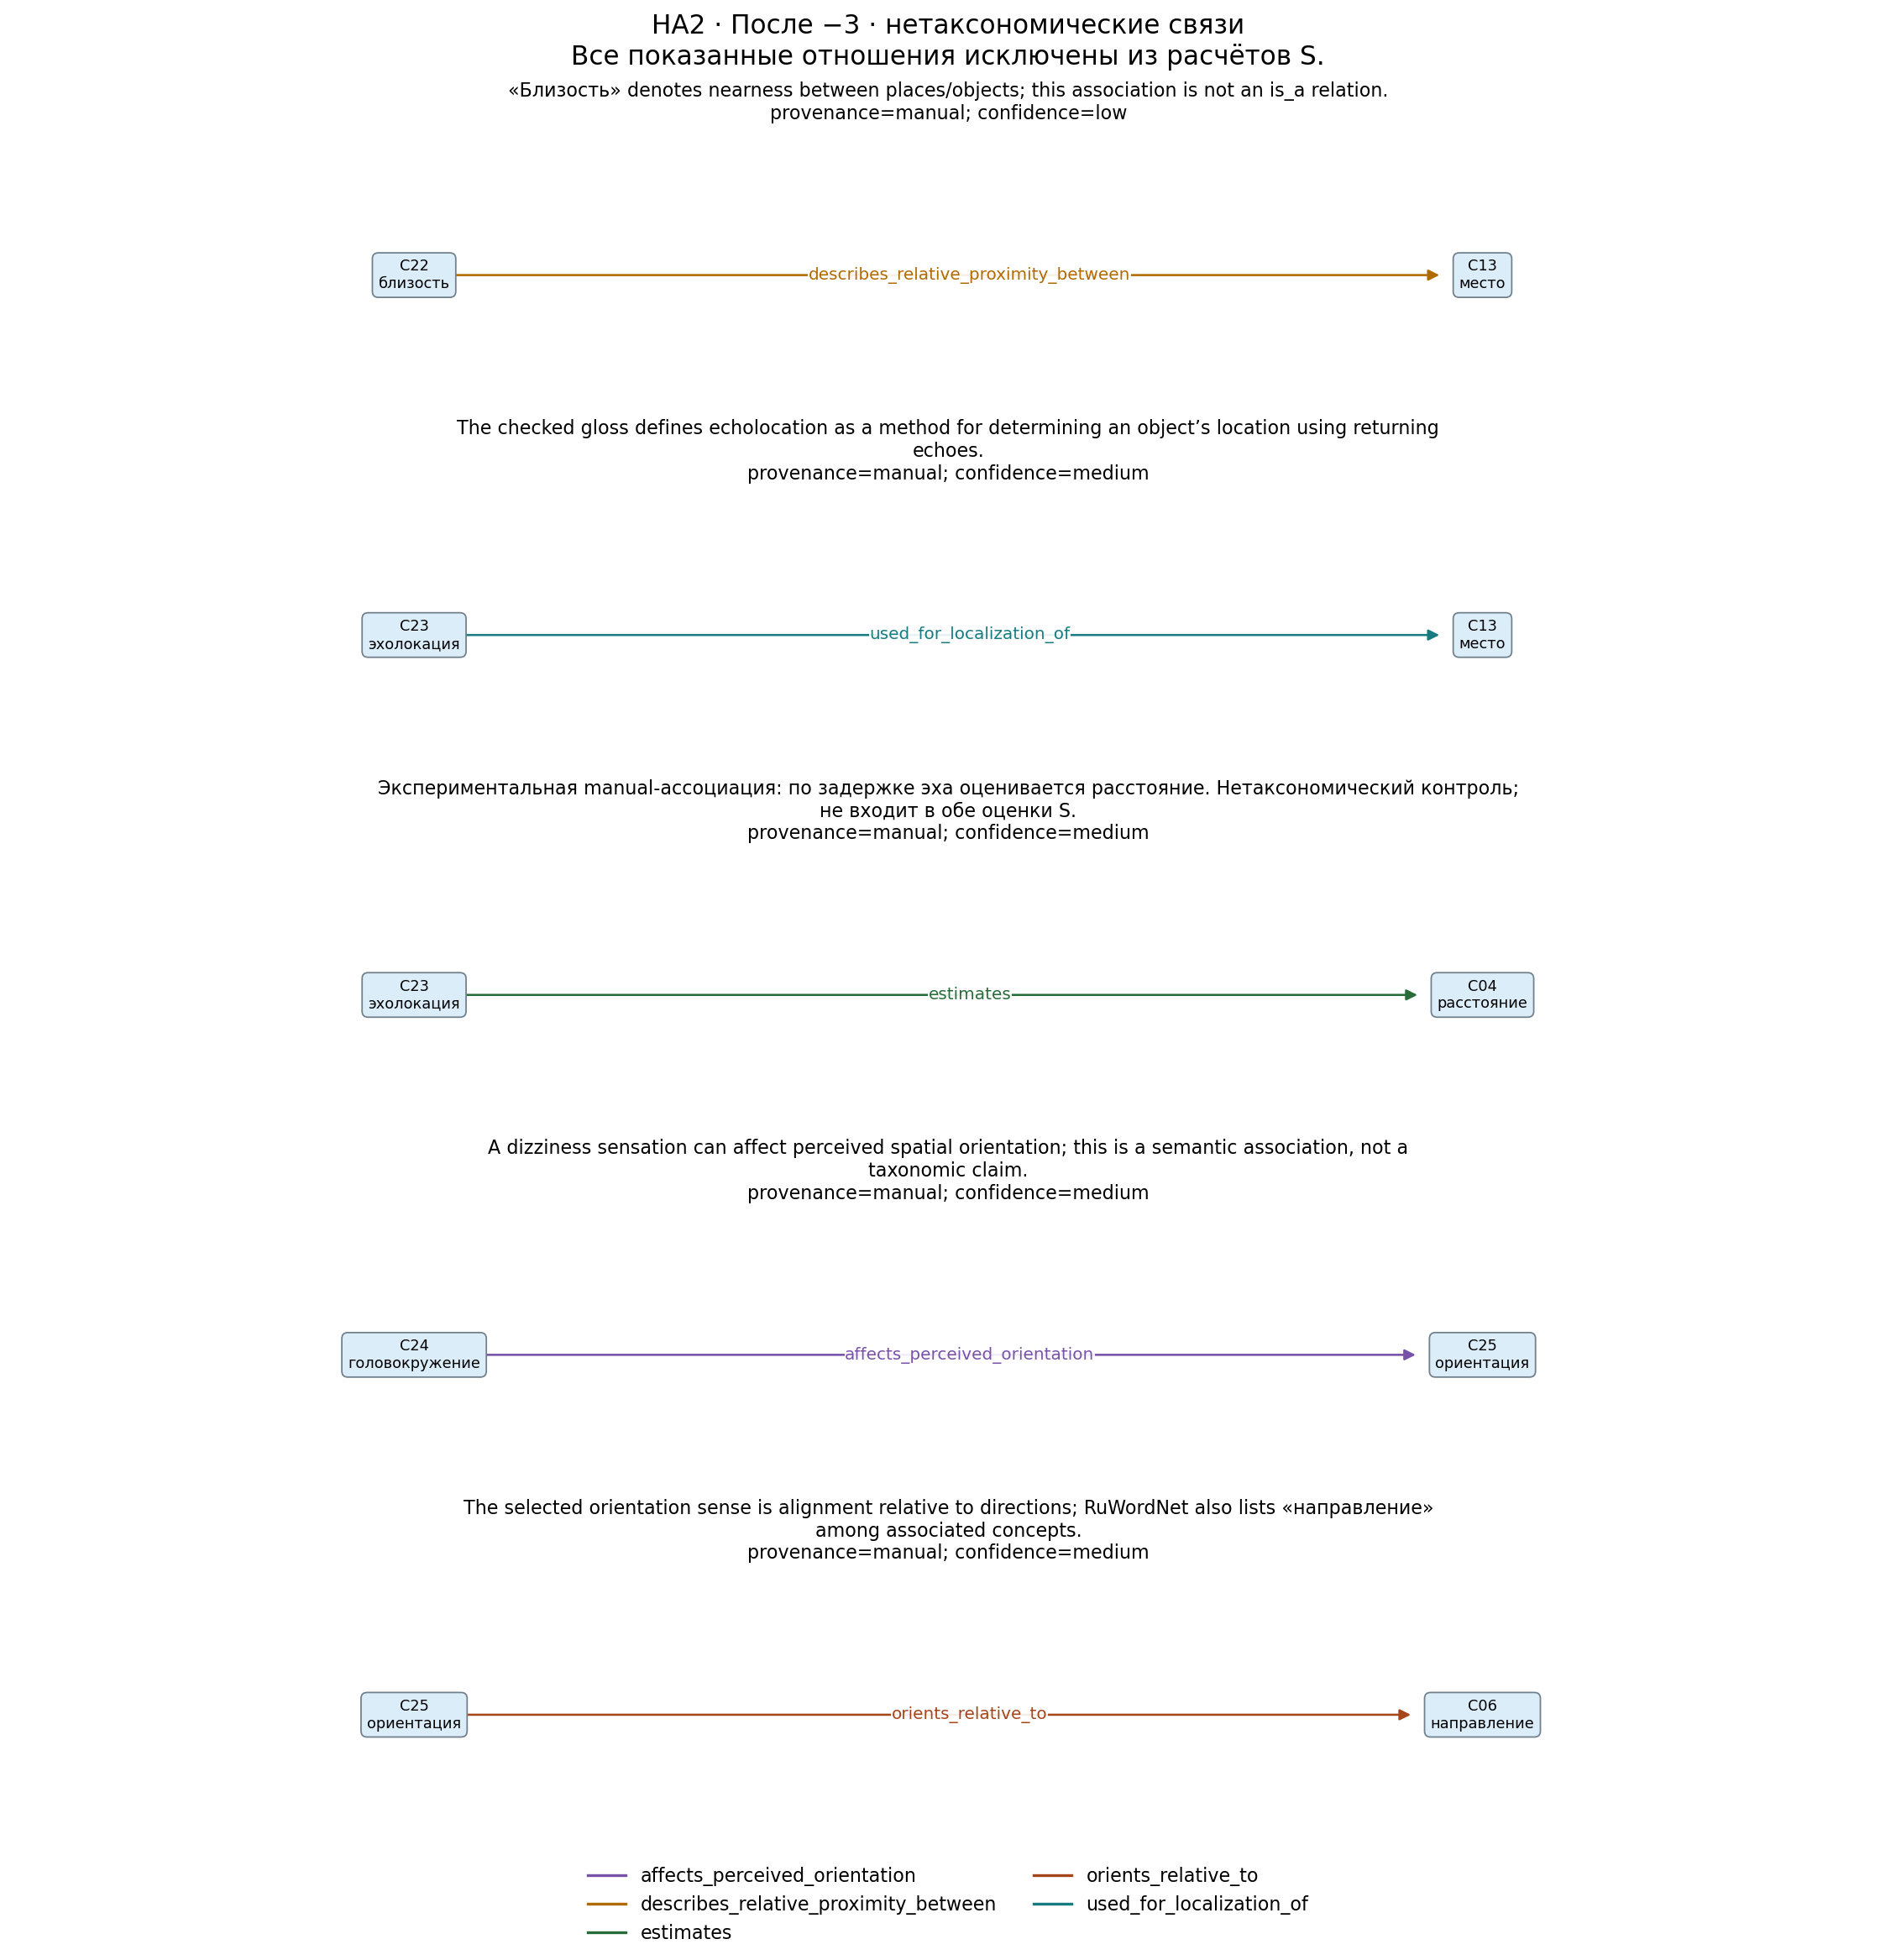

Обновлены 8 изображений в двух форматах: PNG и SVG.


In [11]:
figure_paths = render_artifacts(DATA_DIR)
for name in figure_paths:
    if name.endswith('.png') and name not in ('figures/taxonomy.png', 'figures/non_taxonomic.png'):
        display(Image(filename=str(DATA_DIR / name)))
print('Обновлены 8 изображений в двух форматах: PNG и SVG.')

## 9. Происхождение и границы готовности

`results/artifact_manifest.json` связывает входы, код, source cells notebook, все актуальные таблицы/JSON/изображения и документацию через SHA-256. Outputs и временные метки notebook исключены из его source-хеша, чтобы выполнение не создавало циклическую зависимость.

Независимые тесты отдельно сверяют CSV через BFS, явные пути и множества потомков; проверка манифеста ниже подтверждает согласованность файлов, но не заменяет независимый пересчёт.

Альтернативная версия PR #5 сохранена без изменения в `archive/pr5/`, исключена из текущего комплекта и не используется как вход.

[Итоговая интерпретация](INTERPRETATION.md) и [сценарий с удалением второго родителя](ROLE4.md).

In [12]:
artifact_manifest = write_artifact_manifest(DATA_DIR)
print(verify_artifacts(DATA_DIR))
run_manifest = json.loads((DATA_DIR / 'results/run_manifest.json').read_text())
print({key: run_manifest[key] for key in ('coverage_status', 'perturbation_status',
                                        'artifacts_status', 'interpretation_written')})
print('Актуальный комплект: results/, results/ha1_coverage/, results/perturbation/, figures/.')
print('archive/pr5/ — отдельный архив, не текущие результаты.')

{'verified_files': 67, 'figure_files': 16, 'source_commit': 'e1916dff33a5f25eb263696e0f95088b4d95f168', 'interpretation_written': True}
{'coverage_status': 'computed', 'perturbation_status': 'computed', 'artifacts_status': 'computed', 'interpretation_written': True}
Актуальный комплект: results/, results/ha1_coverage/, results/perturbation/, figures/.
archive/pr5/ — отдельный архив, не текущие результаты.
